# Detector de calidad de manzanas con YOLO · Evaluación 03
### Machine Learning · Universidad Bernardo O'Higgins · Proyecto YOLO

**Integrantes:** Lucas Benítez, Martin Durán, Alonso Plane · **Sección:** 3 · **Docente:** Dr. Eliecer Peña Ancavil · **Entrega:** sábado 7 de noviembre de 2026

**Problema.** Detectar manzanas en una imagen y decir, para cada una, si está en buen estado (`apple`) o dañada (`damaged_apple`). Sirve como apoyo a la selección de fruta por calidad.

**Dataset.** *Apple Sorting* (Roboflow Universe, versión 2): https://universe.roboflow.com/arfiani-nur-sayidah-9lizr/apple-sorting-2bfhk/dataset/2
**Licencia:** License: CC BY 4.0 · **Clases usadas:** `apple`, `damaged_apple`

---
*Este notebook parte de la plantilla de la Clase 10 («Detección de caras con YOLO»), generada por el Doctor Eliecer Peña Ancavil con fines de formación general. Se usa y modifica con fines formativos, citando la fuente.*

**Recorrido**

- Parte 0 · Preparar Google Colab, su GPU y Google Drive.
- Parte 1 · Funciones auxiliares.
- Parte 2 · YOLO tal como viene.
- Parte 3 · El dataset: imágenes, cajas, YAML y revisión de fuga de datos.
- Parte 4 · Transfer learning.
- Parte 5 · ¿Cómo se mide un detector?
- Parte 6 · Fine tuning.
- Parte 7 · Comparar los modelos con Validation y elegir.
- Parte 8 · Evaluación final con Test (una sola vez) y errores.
- Parte 9 · Usar el modelo con imágenes y video externos.
- Parte 10 · Guardar el modelo y los resultados.
- Parte 11 · Lista de verificación antes de entregar.

---
# Parte 0 · Preparar Google Colab y su GPU

## Activar la GPU

`Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → **T4 GPU** → `Guardar`. Esto reinicia la sesión. Si no consiguen GPU, intenten más tarde: entrenar en CPU tarda horas.

## Antes de ejecutar

Todos los archivos del proyecto se leen desde **Google Drive**, así no hay que subirlos a mano en cada sesión.

1. En **Mi unidad** de Google Drive debe existir una carpeta llamada **`yolo_manzanas`** (en minúsculas) con dos archivos:
   - **El ZIP del dataset** de Roboflow en formato YOLO: `Apple Sorting.v2i.yolo26.zip` (Roboflow → `Download Dataset` → formato YOLO → `Download zip to computer`).
   - **Un ZIP con la carpeta `ejemplos/`**, que contiene las **fotos de manzanas que no sean del dataset** y **dos videos `.mp4` de al menos 10 segundos** que tampoco salgan del dataset. El nombre del ZIP puede ser cualquiera; conviene que empiece con `ejemplos`.
2. Al ejecutar la celda **0C**, Colab pide permiso para conectar Drive (una vez por sesión): acepten en la ventana emergente.
3. Si no tienen Drive a mano, el notebook igual corre: el dataset se pide con el selector de archivos de Colab, y las fotos y videos se pueden arrastrar al panel de archivos (`ejemplos.zip`, `video_prueba_1.mp4` y `video_prueba_2.mp4`). Sin fotos ni videos propios usa imágenes de demostración, que **no sirven** como evidencia del informe.

## Instalación

In [1]:
# ============================================================
# PARTE 0A · Instalación (Colab no trae Ultralytics)
# ============================================================
%pip install -q ultralytics

In [2]:
# ============================================================
# PARTE 0B · Librerías, semilla y detección de GPU
# ============================================================
import os
import json
import time
import shutil
import random
import zipfile
import warnings
import urllib.request
from pathlib import Path

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import ultralytics
from ultralytics import YOLO
from PIL import Image, ImageDraw, ImageFont
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# 0 = primera GPU; si no hay GPU, se usa la CPU
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"
NOMBRE_GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU"

print("Ultralytics:", ultralytics.__version__, "| PyTorch:", torch.__version__)
print("Dispositivo:", NOMBRE_GPU)
if DISPOSITIVO == "cpu":
    print("ATENCIÓN: no hay GPU. El entrenamiento tardará horas.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.203 | PyTorch: 2.14.1+cu130
Dispositivo: Tesla T4


## Configuración general: aquí se modifican los hiperparámetros

Todo lo que se puede cambiar está en esta celda. Las carpetas se crean **en la misma carpeta del notebook** (en Colab, `/content`).

In [3]:
# ============================================================
# CONFIGURACIÓN EDITABLE · Un único lugar para hacer cambios
# ============================================================
PARAMETROS = {
    "modelo_base": "yolo26n.pt",      # YOLO26 nano: el más liviano; preentrenado con COCO
    "carpeta_drive": "/content/drive/MyDrive/yolo_manzanas",   # carpeta de Google Drive con el dataset y los ejemplos
    "dataset_zip": "/content/drive/MyDrive/yolo_manzanas/Apple Sorting.v2i.yolo26.zip",  # ZIP del dataset (Roboflow, formato YOLO)

    # === CONFIGURACIÓN DE DRIVE PÚBLICO (ALONSO) ===
    # Reemplacen estos IDs con los IDs reales de los archivos públicos de Alonso
    "drive_publico_dataset_id": "1vhqP5x6YiAEHTpWbY9f3XA6LUorpwuve",
    "drive_publico_ejemplos_id": "1Bb1sj_VXkerGq8U7uwHGdePOWyVWqdBy",
    # ===============================================

    "videos": ["video_prueba_1.mp4", "video_prueba_2.mp4"],   # los dos videos que se analizan en la Parte 9B
    "clases": ["apple", "damaged_apple"],  # clases que se quedan (nombres exactos del data.yaml)
    "fraccion_test": 0.15,            # solo se usa si la versión NO trae Validation o Test y hay que crearlos
    "imgsz": 640,                     # lado (px) al que YOLO redimensiona cada imagen (si va lento: 416)
    "batch": 16,                      # imágenes por lote
    "workers": 2,                     # procesos que cargan imágenes (Colab gratis tiene 2 núcleos)
    "epocas_transfer": 30,            # épocas del transfer learning
    "fraccion_transfer": 1.0,         # dataset chico: se usa todo el Train
    "capas_congeladas": 10,           # se congelan las 10 primeras capas (el backbone)
    "epocas_fine_tuning": 30,         # épocas del fine tuning
    "fraccion_fine_tuning": 1.0,      # todo el Train
    "lr_fine_tuning": 1e-4,           # learning rate bajo: ajustar sin romper lo aprendido
    "paciencia": 10,                  # si en 10 épocas no mejora en Validation, se detiene
    "confianza": 0.25,                # confianza mínima para dibujar una caja
    "cache": "disk",                  # guarda las imágenes preprocesadas en disco
    "horas_maximas_transfer": None,   # opcional: tope de horas (reemplaza a las épocas)
    "horas_maximas_fine_tuning": None,
}
# Ojo: estos valores se pueden ajustar mirando Validation. NUNCA se ajustan mirando Test.

In [4]:
# ============================================================
# CONFIGURACIÓN · Carpetas (todas junto al notebook)
# ============================================================
BASE = Path.cwd()                                  # carpeta del notebook (en Colab: /content)
DATOS = BASE / "datos_manzanas"                    # Train / Validation / Test
RUNS = BASE / "runs_manzanas"                      # lo que guarda Ultralytics en cada entrenamiento
RESULTADOS = BASE / "resultados_manzanas"          # modelos, figuras y cifras para llevarse
FIGURAS = RESULTADOS / "figuras"
for carpeta in (RUNS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

NOMBRES = {0: "apple", 1: "damaged_apple"}         # se vuelven a leer del data.yaml en la Parte 3B
NUMEROS = {"integrantes": ["Lucas Benítez", "Martin Durán", "Alonso Plane"],
           "parametros": PARAMETROS, "dispositivo": NOMBRE_GPU,
           "ultralytics": ultralytics.__version__}   # cifras que se guardan al final

print("Carpeta de trabajo:", BASE)
print(pd.Series(PARAMETROS, name="Valor").to_string())

Carpeta de trabajo: /content
modelo_base                                                         yolo26n.pt
carpeta_drive                             /content/drive/MyDrive/yolo_manzanas
dataset_zip                  /content/drive/MyDrive/yolo_manzanas/Apple Sor...
drive_publico_dataset_id                     1vhqP5x6YiAEHTpWbY9f3XA6LUorpwuve
drive_publico_ejemplos_id                    1Bb1sj_VXkerGq8U7uwHGdePOWyVWqdBy
videos                                [video_prueba_1.mp4, video_prueba_2.mp4]
clases                                                  [apple, damaged_apple]
fraccion_test                                                             0.15
imgsz                                                                      640
batch                                                                       16
workers                                                                      2
epocas_transfer                                                             30
fraccion_transfer      

---
## Conectar Google Drive (celda 0C)

La carpeta **`yolo_manzanas`** de **Mi unidad** guarda el ZIP del dataset y el ZIP con la carpeta `ejemplos/` (fotos y videos). Esta celda conecta Drive y copia esos archivos a `/content` con los nombres que el resto del notebook espera. Si la carpeta no existe, avisa y el notebook sigue con los respaldos descritos en la Parte 0.

In [5]:
# ============================================================
# PARTE 0C · Conectar Google Drive y traer los archivos del proyecto (Soporta Descarga Pública)
# ============================================================
import subprocess

CARPETA_DRIVE = Path(PARAMETROS["carpeta_drive"])
ZIP_DATASET_LOCAL = BASE / "dataset_roboflow.zip"

def descargar_desde_drive_publico(file_id, destino):
    '''Usa gdown para descargar un archivo público de Google Drive dado su ID.'''
    print(f"Descargando {destino.name} desde Google Drive Público...")
    comando = f"gdown --id {file_id} -O {destino}"
    resultado = subprocess.run(comando, shell=True, capture_output=True, text=True)
    if resultado.returncode == 0:
        print(f"¡Descarga exitosa de {destino.name}!")
        return True
    else:
        print(f"No se pudo descargar {destino.name} automáticamente.")
        return False

# Intentamos el método sin montar Drive (Descarga pública directa con los IDs de Alonso)
usando_publico = False

# Validar si se configuraron los IDs públicos
if (PARAMETROS["drive_publico_dataset_id"] != "ID_DEL_ARCHIVO_ZIP_DEL_DATASET_AQUÍ" and
    PARAMETROS["drive_publico_ejemplos_id"] != "ID_DEL_ARCHIVO_EJEMPLOS_ZIP_AQUÍ"):

    # Descargar dataset
    ok_dataset = descargar_desde_drive_publico(PARAMETROS["drive_publico_dataset_id"], ZIP_DATASET_LOCAL)
    # Descargar ejemplos
    ok_ejemplos = descargar_desde_drive_publico(PARAMETROS["drive_publico_ejemplos_id"], BASE / "ejemplos.zip")

    if ok_dataset and ok_ejemplos:
        usando_publico = True
        print("\nUsando archivos descargados directamente desde el Drive público de Alonso. ¡No fue necesario montar tu Drive!")

if not usando_publico:
    print("\nNo se detectaron IDs válidos de Drive Público. Intentando montar el Google Drive tradicional...")
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        print("No estamos en Colab: se usa la ruta de la carpeta tal cual.")
    except Exception as error:
        print("No se pudo conectar Drive:", str(error)[:150])

    if not CARPETA_DRIVE.exists():
        print(f"AVISO: no existe {CARPETA_DRIVE}. Revisen que la carpeta se llame yolo_manzanas y esté en Mi unidad.")
        print("El notebook sigue: el dataset se pedirá con el selector de archivos y las fotos y videos usarán los respaldos.")
    else:
        zips = sorted(CARPETA_DRIVE.glob("*.zip"))
        print(f"Carpeta {CARPETA_DRIVE.name}: {[p.name for p in CARPETA_DRIVE.iterdir()]}")

        # 1) ZIP del dataset
        zip_dataset = Path(PARAMETROS["dataset_zip"])
        if not zip_dataset.exists():
            candidatos = [p for p in zips if "ejemplo" not in p.name.lower()]
            candidatos = [p for p in candidatos if "apple" in p.name.lower() or "sorting" in p.name.lower()] or candidatos[:1]
            zip_dataset = candidatos[0] if candidatos else None
        if zip_dataset is not None:
            shutil.copy2(zip_dataset, ZIP_DATASET_LOCAL)
            print("Dataset copiado desde Drive:", zip_dataset.name)
        else:
            print("AVISO: no encontré el ZIP del dataset en la carpeta de Drive.")

        # 2) ZIP de ejemplos
        resto = [p for p in zips if p != zip_dataset]
        zip_ejemplos = ([p for p in resto if "ejemplo" in p.name.lower()] or resto)[:1]
        if zip_ejemplos:
            shutil.copy2(zip_ejemplos[0], BASE / "ejemplos.zip")
            print("Ejemplos copiados desde Drive:", zip_ejemplos[0].name)
        elif (CARPETA_DRIVE / "ejemplos").is_dir() and not (BASE / "ejemplos").exists():
            shutil.copytree(CARPETA_DRIVE / "ejemplos", BASE / "ejemplos")
            print("Carpeta ejemplos/ copiada desde Drive.")
        else:
            print("AVISO: no encontré el ZIP de ejemplos en Drive.")

Descargando dataset_roboflow.zip desde Google Drive Público...
¡Descarga exitosa de dataset_roboflow.zip!
Descargando ejemplos.zip desde Google Drive Público...
¡Descarga exitosa de ejemplos.zip!

Usando archivos descargados directamente desde el Drive público de Alonso. ¡No fue necesario montar tu Drive!


---
# Parte 1 · Funciones auxiliares

**No necesitas leer este código para seguir la clase, pero sí ejecutar sus cuatro celdas**: el resto del notebook las usa. Están aquí para que el resto del notebook quede limpio.

Si quieres reutilizarlas en tu proyecto, cópialas tal cual: no dependen de este dataset.

In [6]:
# ============================================================
# PARTE 1A · Estilo de los gráficos y guardado
# ============================================================
TRAIN, VALID, TEST = "#4C72B0", "#DD8452", "#C44E52"   # colores fijos del curso
MEJOR, RESTO = "#1F8A70", "#B8C7D9"
TAMANO = {"completa": (13.0, 6.2), "mitad": (6.6, 5.0)}



def estilo():
    '''Estilo del curso. Se vuelve a aplicar en cada gráfico porque Ultralytics cambia el de matplotlib.'''
    sns.set_theme(style="whitegrid", context="talk")
    plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 20, "axes.labelsize": 16,
                         "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 13,
                         "figure.dpi": 100, "savefig.dpi": 200, "font.family": "sans-serif",
                         "font.sans-serif": ["DejaVu Sans"]})


estilo()


def guardar_figura(nombre):
    '''Guarda la figura activa en figuras/ (recortada) y la muestra.'''
    ruta = FIGURAS / nombre
    plt.savefig(ruta, dpi=200, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    plt.show()
    print("Gráfico guardado:", ruta.name)


def copiar_figura(origen, nombre, titulo=None):
    '''Copia a figuras/ un gráfico que generó Ultralytics y lo muestra.'''
    estilo()
    origen = Path(origen)
    if not origen.exists():
        print("No se encontró", origen.name)
        return
    img = Image.open(origen)
    alto = 13.0 * img.height / img.width
    plt.figure(figsize=(13.0, alto))
    plt.imshow(img)
    plt.axis("off")
    if titulo:
        plt.title(titulo)
    guardar_figura(nombre)


def cargar_imagen(ruta):
    '''Abre una imagen como RGB.'''
    return Image.open(ruta).convert("RGB")


def grilla(n, columnas=3, alto_fila=3.1):
    '''Figura con n paneles en filas de `columnas`; los sobrantes quedan en blanco.'''
    filas = int(np.ceil(n / columnas))
    columnas = min(columnas, n)
    fig, ejes = plt.subplots(filas, columnas, figsize=(13.0, alto_fila * filas + 0.6))
    ejes = np.atleast_1d(ejes).ravel()
    for ax in ejes[n:]:
        ax.axis("off")
    return fig, ejes[:n]

In [7]:
# ============================================================
# PARTE 1B · El dataset: carpetas, etiquetas YOLO y YAML
# ============================================================
EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def listar_imagenes(carpeta):
    '''Imágenes de una carpeta, ordenadas por nombre.'''
    carpeta = Path(carpeta)
    if not carpeta.exists():
        return []
    return sorted(p for p in carpeta.iterdir() if p.suffix.lower() in EXTENSIONES)


def buscar_split(raiz, split):
    '''Busca un split en las dos estructuras habituales:
    images/train + labels/train   o   train/images + train/labels.'''
    raiz = Path(raiz)
    for img, lbl in [(raiz / "images" / split, raiz / "labels" / split),
                     (raiz / split / "images", raiz / split / "labels")]:
        if img.exists() and lbl.exists():
            return img, lbl
    if split == "val":                       # Roboflow llama "valid" a Validation
        return buscar_split(raiz, "valid")
    return None, None


def _pares(carpeta_img, carpeta_lbl):
    '''Pares (imagen, etiqueta). Una imagen sin .txt es una imagen sin objetos.'''
    return [(img, Path(carpeta_lbl) / f"{img.stem}.txt") for img in listar_imagenes(carpeta_img)]


def _copiar_pares(pares, destino, split):
    '''Copia imágenes y etiquetas a destino/images/split y destino/labels/split.'''
    (destino / "images" / split).mkdir(parents=True, exist_ok=True)
    (destino / "labels" / split).mkdir(parents=True, exist_ok=True)
    for img, lbl in pares:
        shutil.copy2(img, destino / "images" / split / img.name)
        if lbl.exists():
            shutil.copy2(lbl, destino / "labels" / split / lbl.name)


def escribir_yaml(destino, nombres):
    '''Escribe data.yaml: dónde están las imágenes y cómo se llama cada clase.'''
    contenido = {"path": str(Path(destino).resolve()), "train": "images/train",
                 "val": "images/val", "test": "images/test", "names": nombres}
    ruta = Path(destino) / "data.yaml"
    with open(ruta, "w", encoding="utf-8") as f:
        yaml.safe_dump(contenido, f, allow_unicode=True, sort_keys=False)
    return ruta


def crear_dataset_de_trabajo(origen, destino, nombres, fraccion=0.15, semilla=42):
    '''Reorganiza el dataset en Train / Validation / Test y escribe data.yaml.

    - Si trae train y val: conserva val y aparta una fracción de train como test.
    - Si trae train y test: conserva test y aparta una fracción de train como val.
    - Si trae los tres: los conserva.
    - Si solo trae train: aparta val y test desde train.
    OJO: si el dataset trae copias aumentadas (Roboflow), NO lo vuelvas a repartir.'''
    origen, destino = Path(origen), Path(destino)
    if destino.exists():
        shutil.rmtree(destino)
    splits = {s: buscar_split(origen, s) for s in ("train", "val", "test")}
    if splits["train"][0] is None:
        raise FileNotFoundError(f"No encontré un split 'train' en {origen}")
    rng = random.Random(semilla)
    train = _pares(*splits["train"])
    rng.shuffle(train)
    n = max(1, int(len(train) * fraccion))
    if splits["val"][0] and splits["test"][0]:
        partes = {"train": train, "val": _pares(*splits["val"]), "test": _pares(*splits["test"])}
        print("El dataset ya trae train, val y test: se conservan.")
    elif splits["val"][0]:
        partes = {"train": train[n:], "val": _pares(*splits["val"]), "test": train[:n]}
        print(f"Trae train y val: se conserva val y se aparta el {fraccion:.0%} de train como test.")
    elif splits["test"][0]:
        partes = {"train": train[n:], "val": train[:n], "test": _pares(*splits["test"])}
        print(f"Trae train y test: se conserva test y se aparta el {fraccion:.0%} de train como val.")
    else:
        partes = {"train": train[2 * n:], "val": train[:n], "test": train[n:2 * n]}
        print(f"Solo trae train: se aparta un {fraccion:.0%} para val y otro para test.")
    for split, pares in partes.items():
        _copiar_pares(pares, destino, split)
    ruta_yaml = escribir_yaml(destino, nombres)
    print("Dataset de trabajo en:", destino)
    return ruta_yaml


def descomprimir_dataset(ruta_zip, destino):
    '''Descomprime el ZIP de un dataset en formato YOLO y devuelve la carpeta donde está su data.yaml.'''
    ruta_zip, destino = Path(ruta_zip), Path(destino)
    if not ruta_zip.exists():
        raise FileNotFoundError(f"No encontré {ruta_zip}. Déjenlo junto al notebook o súbanlo en Colab.")
    if destino.exists():
        shutil.rmtree(destino)
    with zipfile.ZipFile(ruta_zip) as z:
        z.extractall(destino)
    yamls = sorted((p for p in destino.rglob("data.yaml") if "__MACOSX" not in str(p)), key=lambda p: len(p.parts))
    if not yamls:
        raise FileNotFoundError("El ZIP no trae un data.yaml. Descárguenlo de Roboflow en formato YOLO.")
    raiz = yamls[0].parent
    print("Dataset descomprimido en:", raiz)
    for split in ("train", "val", "test"):
        img, _ = buscar_split(raiz, split)
        print(f"  {split}: {len(listar_imagenes(img)) if img else 0} imágenes")
    return raiz


def leer_nombres(ruta_yaml):
    '''Nombres de las clases de un data.yaml, como diccionario {número: nombre}.'''
    with open(ruta_yaml, encoding="utf-8") as f:
        nombres = yaml.safe_load(f)["names"]
    return dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}


def leer_cajas(ruta_txt, ancho, alto):
    '''Lee un .txt de YOLO y devuelve (clase, x1, y1, x2, y2) en píxeles.'''
    cajas = []
    ruta_txt = Path(ruta_txt)
    if not ruta_txt.exists():
        return cajas
    for linea in ruta_txt.read_text().split("\n"):
        partes = linea.split()
        if len(partes) < 5:
            continue
        c, xc, yc, w, h = int(partes[0]), *map(float, partes[1:5])
        cajas.append((c, (xc - w / 2) * ancho, (yc - h / 2) * alto,
                      (xc + w / 2) * ancho, (yc + h / 2) * alto))
    return cajas


def contar_dataset(raiz, nombres):
    '''Cuántas imágenes, cajas e imágenes sin objetos hay en cada split.'''
    filas = []
    for split in ("train", "val", "test"):
        imgs = listar_imagenes(Path(raiz) / "images" / split)
        n_cajas, vacias = 0, 0
        por_clase = {nombre: 0 for nombre in nombres.values()}
        for img in imgs:
            txt = Path(raiz) / "labels" / split / f"{img.stem}.txt"
            lineas = [l.split() for l in txt.read_text().split("\n") if l.strip()] if txt.exists() else []
            n_cajas += len(lineas)
            vacias += len(lineas) == 0
            for l in lineas:
                por_clase[nombres[int(l[0])]] += 1
        filas.append({"Split": split, "Imágenes": len(imgs), "Cajas": n_cajas,
                      "Imágenes sin objetos": vacias, **por_clase})
    return pd.DataFrame(filas).set_index("Split")


def dibujar_cajas(img, cajas, nombres, color, confianzas=None, grosor=None):
    '''Dibuja cajas (clase, x1, y1, x2, y2) sobre una copia de la imagen.'''
    img = img.copy()
    d = ImageDraw.Draw(img)
    grosor = grosor or max(3, img.width // 200)
    for k, (c, x1, y1, x2, y2) in enumerate(cajas):
        d.rectangle([x1, y1, x2, y2], outline=color, width=grosor)
        texto = nombres.get(c, str(c)) + (f" {confianzas[k]:.2f}" if confianzas is not None else "")
        d.text((x1 + 4, max(0, y1 - 14)), texto, fill=color)
    return img


def mostrar_muestras(raiz, split, nombres, n=4, nombre=None):
    '''n imágenes al azar con sus cajas reales.'''
    estilo()
    imgs = listar_imagenes(Path(raiz) / "images" / split)
    elegidas = random.Random(SEMILLA).sample(imgs, min(n, len(imgs)))
    fig, ejes = plt.subplots(1, len(elegidas), figsize=TAMANO["completa"])
    for ax, ruta in zip(np.atleast_1d(ejes), elegidas):
        img = cargar_imagen(ruta)
        cajas = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        ax.imshow(dibujar_cajas(img, cajas, nombres, TEST))
        ax.set_title(f"{len(cajas)} caja(s)", fontsize=16)
        ax.axis("off")
    fig.suptitle(f"Imágenes de {split} con sus cajas reales", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)


def explicar_etiqueta(raiz, split, nombres, nombre=None, max_cajas=3):
    '''Una imagen con sus cajas al lado del contenido de su archivo .txt.'''
    estilo()
    candidatos = []
    for ruta in listar_imagenes(Path(raiz) / "images" / split)[:800]:
        txt = Path(raiz) / "labels" / split / f"{ruta.stem}.txt"
        lineas = [l for l in txt.read_text().split("\n") if l.strip()] if txt.exists() else []
        if not lineas:
            continue
        with Image.open(ruta) as im:
            horizontal = im.width >= im.height
        n = len(lineas)
        puntaje = (0 if 2 <= n <= max_cajas else 1 if n == 1 else 2) + (0 if horizontal else 3)
        candidatos.append((puntaje, ruta.name, ruta, txt, lineas))
    _, _, ruta, txt, lineas = min(candidatos)          # ideal: foto horizontal con 2 o 3 cajas
    img = cargar_imagen(ruta)
    cajas = leer_cajas(txt, img.width, img.height)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=TAMANO["completa"], gridspec_kw={"width_ratios": [1.25, 1]})
    a1.imshow(dibujar_cajas(img, cajas, nombres, TEST))
    a1.set_title(f"La imagen ({img.width} × {img.height} px)", fontsize=16)
    a1.axis("off")
    a2.axis("off")
    a2.set_title("Su archivo .txt", fontsize=16)
    redondear = lambda l: " ".join([l.split()[0]] + [f"{float(v):.4f}" for v in l.split()[1:5]])
    mostrar = [redondear(l) for l in lineas[:6]] + (["…"] if len(lineas) > 6 else [])
    texto = "\n".join(mostrar)
    texto += ("\n\nclase x_centro y_centro ancho alto\n\nMedidas divididas por el ancho\n"
              "y el alto de la imagen\n(aquí, redondeadas a 4 decimales)")
    a2.text(0.02, 0.5, texto, family="monospace", fontsize=16, va="center")
    fig.suptitle("Una imagen = un archivo .txt con una línea por caja", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)
    return ruta, lineas


def filtrar_clases(origen, destino, conservar):
    '''Crea una copia del dataset solo con las clases de la lista `conservar`.

    Renumera las clases desde 0 y escribe un data.yaml nuevo. Las imágenes que quedan
    sin cajas se conservan: sirven como ejemplos de "no hay nada".
    Ejemplo: filtrar_clases("datos_zip", "datos_filtrados", ["apple", "damaged_apple"])'''
    origen, destino = Path(origen), Path(destino)
    with open(origen / "data.yaml", encoding="utf-8") as f:
        info = yaml.safe_load(f)
    nombres = info["names"]
    nombres = dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}
    faltan = [c for c in conservar if c not in nombres.values()]
    if faltan:
        raise ValueError(f"Estas clases no existen: {faltan}. Disponibles: {list(nombres.values())}")
    nuevo_id = {viejo: conservar.index(nombre) for viejo, nombre in nombres.items() if nombre in conservar}
    if destino.exists():
        shutil.rmtree(destino)
    for split in ("train", "val", "test"):
        carpeta_img, carpeta_lbl = buscar_split(origen, split)
        if carpeta_img is None:
            continue
        (destino / "images" / split).mkdir(parents=True, exist_ok=True)
        (destino / "labels" / split).mkdir(parents=True, exist_ok=True)
        for img in listar_imagenes(carpeta_img):
            shutil.copy2(img, destino / "images" / split / img.name)
            lbl = Path(carpeta_lbl) / f"{img.stem}.txt"
            lineas = []
            if lbl.exists():
                for linea in lbl.read_text().split("\n"):
                    partes = linea.split()
                    if partes and int(partes[0]) in nuevo_id:
                        lineas.append(" ".join([str(nuevo_id[int(partes[0])])] + partes[1:]))
            (destino / "labels" / split / f"{img.stem}.txt").write_text("\n".join(lineas))
    ruta_yaml = escribir_yaml(destino, {i: n for i, n in enumerate(conservar)})
    print("Dataset filtrado en:", destino)
    print(contar_dataset(destino, {i: n for i, n in enumerate(conservar)}))
    return ruta_yaml

In [8]:
# ============================================================
# PARTE 1C · Entrenar, evaluar y graficar
# ============================================================
POR_CLASE = {}   # métricas por clase de cada evaluación (la llena evaluar)


def entrenar(pesos_iniciales, nombre, epocas, fraccion, congelar=None, optimizador="auto",
             lr0=None, horas=None):
    '''Entrena YOLO sobre DATA_YAML y devuelve (ruta de best.pt, segundos, carpeta del run).'''
    modelo = YOLO(pesos_iniciales)
    extra = {"lr0": lr0} if lr0 else {}
    if horas:
        extra["time"] = horas                      # tope de horas: reemplaza a las épocas
    inicio = time.perf_counter()
    modelo.train(data=str(DATA_YAML), epochs=epocas, imgsz=PARAMETROS["imgsz"],
                 batch=PARAMETROS["batch"], fraction=fraccion, freeze=congelar,
                 optimizer=optimizador, cache=PARAMETROS["cache"], workers=PARAMETROS["workers"],
                 device=DISPOSITIVO, seed=SEMILLA, project=str(RUNS), name=nombre,
                 patience=PARAMETROS["paciencia"], exist_ok=True, plots=True, verbose=False, **extra)
    segundos = time.perf_counter() - inicio
    carpeta = RUNS / nombre
    print(f"{nombre}: {segundos / 60:.1f} minutos. Pesos en {carpeta / 'weights' / 'best.pt'}")
    return carpeta / "weights" / "best.pt", segundos, carpeta


def leer_resultados(carpeta_run):
    '''results.csv de un entrenamiento, con los nombres de columna limpios.'''
    tabla = pd.read_csv(Path(carpeta_run) / "results.csv")
    tabla.columns = tabla.columns.str.strip()
    return tabla


def graficar_curvas(carpeta_run, titulo, nombre):
    '''Pérdida de las cajas (Train y Validation) y mAP por época, con la mejor época marcada.'''
    estilo()
    t = leer_resultados(carpeta_run)
    mejor = int(t["metrics/mAP50-95(B)"].idxmax())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=TAMANO["completa"])
    a1.plot(t["epoch"], t["train/box_loss"], color=TRAIN, lw=3, marker="o", label="Train")
    a1.plot(t["epoch"], t["val/box_loss"], color=VALID, lw=3, marker="o", label="Validation")
    a1.set_title("Pérdida de las cajas")
    a2.plot(t["epoch"], t["metrics/mAP50(B)"], color=VALID, lw=3, marker="o", label="mAP50")
    a2.plot(t["epoch"], t["metrics/mAP50-95(B)"], color=VALID, lw=3, marker="s", ls="--", label="mAP50-95")
    a2.set_ylim(0, 1)
    a2.set_title("mAP en Validation")
    for ax in (a1, a2):
        ax.axvline(t["epoch"][mejor], color=MEJOR, lw=2, ls=":")
        ax.set_xlabel("Época")
        ax.legend()
    a2.text(t["epoch"][mejor], 0.04, f" mejor época: {int(t['epoch'][mejor])}", color=MEJOR, fontsize=14)
    fig.suptitle(titulo, fontsize=21, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)
    return int(t["epoch"][mejor]), len(t)


def evaluar(ruta_pesos, split, nombre):
    '''Precision, recall, mAP50 y mAP50-95 en un split (val o test), al mismo imgsz del entrenamiento.'''
    m = YOLO(ruta_pesos).val(data=str(DATA_YAML), split=split, imgsz=PARAMETROS["imgsz"], batch=16,
                             conf=0.001, device=DISPOSITIVO, plots=True, project=str(RUNS),
                             name=f"eval_{nombre}_{split}", exist_ok=True, verbose=False)
    resultado = {"Precision": float(m.box.mp), "Recall": float(m.box.mr),
                 "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}
    por_clase = {}                                   # lo mismo, pero separado por clase
    try:
        for pos, idx in enumerate(m.box.ap_class_index):
            p, r, a50, a = m.box.class_result(pos)
            por_clase[m.names[int(idx)]] = {"Precision": float(p), "Recall": float(r),
                                            "mAP50": float(a50), "mAP50-95": float(a)}
    except Exception as error:
        print("No se pudo calcular por clase:", error)
    POR_CLASE[f"{nombre}_{split}"] = por_clase
    print(f"{nombre} en {split}:", {k: round(v, 3) for k, v in resultado.items()})
    return resultado, Path(m.save_dir)


def graficar_metricas(metricas, titulo, nombre, color=VALID):
    '''Barras con las cuatro métricas de un modelo.'''
    estilo()
    plt.figure(figsize=TAMANO["completa"])
    barras = plt.bar(list(metricas), list(metricas.values()), color=color, width=0.6)
    for b, v in zip(barras, metricas.values()):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=18, fontweight="bold")
    plt.ylim(0, 1.1)
    plt.title(titulo)
    guardar_figura(nombre)


def comparar_modelos(tabla, titulo, nombre, elegido=None):
    '''Barras agrupadas: una métrica por grupo, un modelo por color (el elegido en verde).'''
    estilo()
    df = pd.DataFrame(tabla).T
    x = np.arange(len(df.columns))
    ancho = 0.8 / len(df)
    plt.figure(figsize=TAMANO["completa"])
    for k, (modelo, fila) in enumerate(df.iterrows()):
        color = MEJOR if modelo == elegido else RESTO
        barras = plt.bar(x + k * ancho, fila.values, ancho, label=modelo, color=color, edgecolor="white")
        for b, v in zip(barras, fila.values):
            plt.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.3f}", ha="center", fontsize=14, fontweight="bold")
    plt.xticks(x + ancho * (len(df) - 1) / 2, df.columns)
    plt.ylim(0, 1.1)
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=len(df), frameon=False)
    plt.title(titulo)
    guardar_figura(nombre)


def iou(a, b):
    '''Intersección sobre unión de dos cajas (x1, y1, x2, y2).'''
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def graficar_iou(nombre):
    '''Tres detecciones de la misma manzana real, de buena a mala, con su IoU.'''
    estilo()
    real = (2, 2, 8, 9)
    predichas = [(2.3, 2.2, 8.2, 9.1), (3.5, 3.5, 9.5, 10.2), (5.5, 6, 11, 12.5)]
    fig, ejes = plt.subplots(1, 3, figsize=TAMANO["completa"])
    for ax, p in zip(ejes, predichas):
        valor = iou(real, p)
        ax.add_patch(plt.Rectangle(real[:2], real[2] - real[0], real[3] - real[1], fill=False, ec=TEST, lw=4))
        ax.add_patch(plt.Rectangle(p[:2], p[2] - p[0], p[3] - p[1], fill=False, ec=MEJOR, lw=4, ls="--"))
        acierto = valor >= 0.5
        ax.set_title(f"IoU = {valor:.2f}\n" + ("cuenta como acierto" if acierto else "NO cuenta (IoU < 0,5)"),
                     color=MEJOR if acierto else TEST, fontsize=17)
        ax.set_xlim(0, 13); ax.set_ylim(13, 0); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
    ejes[0].legend(handles=[plt.Line2D([], [], color=TEST, lw=4, label="caja real"),
                            plt.Line2D([], [], color=MEJOR, lw=4, ls="--", label="caja predicha")],
                   loc="lower left", fontsize=13)
    fig.suptitle("IoU: cuánto se superpone la caja predicha con la real", fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)


def contar_aciertos(ruta_pesos, raiz, split, nombres, conf, iou_minimo=0.5, max_imagenes=1500):
    '''Aciertos, falsas detecciones y objetos perdidos con una confianza mínima dada.
    Una detección es acierto si su IoU con una caja real (de la misma clase) llega a iou_minimo.'''
    modelo = YOLO(ruta_pesos)
    imgs = listar_imagenes(Path(raiz) / "images" / split)[:max_imagenes]
    vp = fp = fn = 0
    for ruta in imgs:
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=conf, device=DISPOSITIVO, verbose=False)[0]
        usadas = set()
        orden = np.argsort(-r.boxes.conf.cpu().numpy()) if len(r.boxes) else []
        for i in orden:
            c, caja = int(r.boxes.cls[i]), r.boxes.xyxy[i].tolist()
            mejor, j_mejor = 0, None
            for j, (cr, *xyxy) in enumerate(reales):
                if j not in usadas and cr == c:
                    v = iou(caja, xyxy)
                    if v > mejor:
                        mejor, j_mejor = v, j
            if mejor >= iou_minimo:
                vp += 1
                usadas.add(j_mejor)
            else:
                fp += 1
        fn += len(reales) - len(usadas)
    resultado = {"Aciertos": vp, "Falsas detecciones": fp, "Objetos perdidos": fn,
                 "Precision": vp / max(1, vp + fp), "Recall": vp / max(1, vp + fn), "Imágenes": len(imgs)}
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in resultado.items()})
    return resultado


def graficar_aciertos(conteo, titulo, nombre):
    '''Barras de aciertos, falsas detecciones y objetos perdidos, con precision y recall.'''
    estilo()
    etiquetas = ["Aciertos", "Falsas detecciones", "Objetos perdidos"]
    valores = [conteo[e] for e in etiquetas]
    plt.figure(figsize=TAMANO["completa"])
    barras = plt.bar(etiquetas, valores, color=[MEJOR, TEST, VALID], width=0.6)
    for b, v in zip(barras, valores):
        plt.text(b.get_x() + b.get_width() / 2, v * 1.01 + 1, f"{v:,}".replace(",", "."), ha="center",
                 fontsize=20, fontweight="bold")
    plt.ylim(0, max(valores) * 1.18 + 1)
    plt.title(titulo)
    plt.figtext(0.5, -0.04, f"Precision = aciertos / (aciertos + falsas) = {conteo['Precision']:.2f}     "
                f"Recall = aciertos / (aciertos + perdidos) = {conteo['Recall']:.2f}",
                ha="center", fontsize=16)
    guardar_figura(nombre)


def galeria_real_vs_predicho(ruta_pesos, raiz, split, nombres, n=6, nombre=None):
    '''Cajas reales (rojo) y predichas (verde) sobre las mismas imágenes.'''
    estilo()
    modelo = YOLO(ruta_pesos)
    imgs = listar_imagenes(Path(raiz) / "images" / split)
    elegidas = random.Random(SEMILLA + 1).sample(imgs, min(n, len(imgs)))
    fig, ejes = grilla(len(elegidas), columnas=3, alto_fila=3.0)
    for ax, ruta in zip(ejes, elegidas):
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        pred = [(int(c), *xyxy) for c, xyxy in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
        img = dibujar_cajas(img, reales, nombres, TEST)
        img = dibujar_cajas(img, pred, nombres, MEJOR, confianzas=r.boxes.conf.tolist())
        ax.imshow(img)
        ax.set_title(f"Reales: {len(reales)} · Detectadas: {len(pred)}", fontsize=14)
        ax.axis("off")
    fig.suptitle("Rojo: caja real · Verde: lo que detecta el modelo", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)

In [9]:
# ============================================================
# PARTE 1D · Usar el modelo: imágenes y video
# ============================================================
def predecir_imagenes(ruta_pesos, imagenes, carpeta_salida, titulo, nombre=None, max_mostrar=6):
    '''Detecta en una lista de imágenes, guarda cada resultado y muestra una galería.'''
    estilo()
    carpeta_salida = Path(carpeta_salida)
    carpeta_salida.mkdir(parents=True, exist_ok=True)
    modelo = YOLO(ruta_pesos)
    filas, dibujadas = [], []
    for ruta in imagenes:
        r = modelo.predict(str(ruta), imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        dibujo = Image.fromarray(r.plot()[:, :, ::-1])            # r.plot() entrega BGR
        dibujo.save(carpeta_salida / f"{Path(ruta).stem}_detectado.jpg")
        clases = [r.names[int(c)] for c in r.boxes.cls.tolist()]
        filas.append({"imagen": Path(ruta).name, "detecciones": len(clases),
                      "clases": ", ".join(sorted(set(clases)))})
        dibujadas.append(dibujo)
    n = min(max_mostrar, len(dibujadas))
    fig, ejes = grilla(n, columnas=3, alto_fila=3.0)
    for ax, img, fila in zip(ejes, dibujadas, filas):
        ax.imshow(img)
        ax.set_title(f"{fila['detecciones']} detección(es)", fontsize=14)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)
    print("Resultados guardados en:", carpeta_salida)
    return pd.DataFrame(filas)


def crear_video_desde_imagenes(imagenes, ruta_video, segundos_por_imagen=1.0, fps=10, ancho=1280, alto=720):
    '''Arma un video corto con imágenes (sirve si no tienes un video a mano).'''
    escritor = cv2.VideoWriter(str(ruta_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ancho, alto))
    for ruta in imagenes:
        img = cargar_imagen(ruta)
        img.thumbnail((ancho, alto))
        lienzo = Image.new("RGB", (ancho, alto))
        lienzo.paste(img, ((ancho - img.width) // 2, (alto - img.height) // 2))
        cuadro = cv2.cvtColor(np.array(lienzo), cv2.COLOR_RGB2BGR)
        for _ in range(int(segundos_por_imagen * fps)):
            escritor.write(cuadro)
    escritor.release()
    return Path(ruta_video)


def predecir_video(ruta_pesos, ruta_video, ruta_salida):
    '''Detecta cuadro a cuadro, guarda el video con las cajas y devuelve una tabla por cuadro.'''
    modelo = YOLO(ruta_pesos)
    lector = cv2.VideoCapture(str(ruta_video))
    fps = lector.get(cv2.CAP_PROP_FPS) or 25
    ancho, alto = int(lector.get(cv2.CAP_PROP_FRAME_WIDTH)), int(lector.get(cv2.CAP_PROP_FRAME_HEIGHT))
    escritor = cv2.VideoWriter(str(ruta_salida), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ancho, alto))
    filas, cuadros_muestra, k = [], [], 0
    while True:
        ok, cuadro = lector.read()
        if not ok:
            break
        t = time.perf_counter()
        r = modelo.predict(cuadro, imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        ms = (time.perf_counter() - t) * 1000
        dibujo = r.plot()
        escritor.write(dibujo)
        filas.append({"cuadro": k, "segundo": k / fps, "detecciones": len(r.boxes), "ms": ms})
        if k % max(1, int(fps)) == 0:
            cuadros_muestra.append(dibujo[:, :, ::-1])
        k += 1
    lector.release()
    escritor.release()
    tabla = pd.DataFrame(filas)
    print(f"{k} cuadros procesados ({k / fps:.1f} s de video). "
          f"Velocidad media: {1000 / tabla['ms'].mean():.1f} cuadros por segundo. Guardado en {ruta_salida}")
    return tabla, cuadros_muestra


def graficar_detecciones_por_cuadro(tabla, titulo, nombre):
    '''Cuántos objetos detecta el modelo en cada momento del video.'''
    estilo()
    plt.figure(figsize=TAMANO["completa"])
    plt.plot(tabla["segundo"], tabla["detecciones"], color=MEJOR, lw=2.5, drawstyle="steps-post")
    plt.fill_between(tabla["segundo"], tabla["detecciones"], color=MEJOR, alpha=0.15, step="post")
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))      # se cuentan objetos enteros
    plt.ylim(bottom=0)
    plt.xlabel("Segundo del video")
    plt.ylabel("Objetos detectados")
    plt.title(titulo)
    guardar_figura(nombre)


def galeria_cuadros(cuadros, titulo, nombre, n=4):
    '''Algunos cuadros del video procesado.'''
    estilo()
    paso = max(1, len(cuadros) // n)
    elegidos = cuadros[::paso][:n]
    fig, ejes = grilla(len(elegidos), columnas=2, alto_fila=3.6)
    for ax, c in zip(ejes, elegidos):
        ax.imshow(c)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)

In [10]:
# ============================================================
# PARTE 1E · Funciones nuevas para este proyecto
# (revisión de fuga de datos, tamaño de cajas, distribución y errores)
# ============================================================
import hashlib


def _base_roboflow(nombre):
    '''Nombre de la foto original: Roboflow agrega ".rf.<código>" a cada copia aumentada.'''
    return Path(nombre).name.split(".rf.")[0]


def _md5(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()


def revisar_fuga(raiz):
    '''Busca copias de una misma foto dentro de un split y entre splits.
    Devuelve dos tablas: una por split y otra con los cruces Train-Val, Train-Test y Val-Test.
    Cruces distintos de 0 = fuga de datos (métricas infladas).'''
    info = {}
    for split in ("train", "val", "test"):
        imgs = listar_imagenes(Path(raiz) / "images" / split)
        info[split] = {"bases": [_base_roboflow(p.name) for p in imgs], "hashes": [_md5(p) for p in imgs]}
    por_split = pd.DataFrame([{"Split": s, "Imágenes": len(d["bases"]),
                               "Fotos originales distintas": len(set(d["bases"])),
                               "Copias aumentadas dentro del split": len(d["bases"]) - len(set(d["bases"])),
                               "Archivos idénticos dentro del split": len(d["hashes"]) - len(set(d["hashes"]))}
                              for s, d in info.items()]).set_index("Split")
    cruces = pd.DataFrame([{"Par": f"{a} ↔ {b}",
                            "Fotos originales compartidas": len(set(info[a]["bases"]) & set(info[b]["bases"])),
                            "Archivos idénticos compartidos": len(set(info[a]["hashes"]) & set(info[b]["hashes"]))}
                           for a, b in (("train", "val"), ("train", "test"), ("val", "test"))]).set_index("Par")
    return por_split, cruces


def tamano_cajas(raiz, nombres):
    '''Tamaño de las cajas como % del área de la imagen, por clase.
    Cajas muy pequeñas pierden casi todos sus píxeles al redimensionar a imgsz.'''
    filas = []
    for split in ("train", "val", "test"):
        for img in listar_imagenes(Path(raiz) / "images" / split):
            txt = Path(raiz) / "labels" / split / f"{img.stem}.txt"
            if not txt.exists():
                continue
            for linea in txt.read_text().split("\n"):
                p = linea.split()
                if len(p) >= 5:
                    filas.append({"clase": nombres[int(p[0])], "area_pct": float(p[3]) * float(p[4]) * 100})
    df = pd.DataFrame(filas)
    return df.groupby("clase")["area_pct"].agg(cajas="count", minimo="min", mediana="median", maximo="max").round(2)


def graficar_distribucion(conteo, nombres, nombre):
    '''Barras con las cajas de cada clase en Train, Validation y Test.'''
    estilo()
    clases = list(nombres.values())
    colores = [MEJOR, TEST, VALID, TRAIN]
    x = np.arange(len(conteo.index))
    ancho = 0.8 / len(clases)
    tope = float(conteo[clases].values.max())
    plt.figure(figsize=TAMANO["completa"])
    for k, c in enumerate(clases):
        barras = plt.bar(x + k * ancho, conteo[c].values, ancho, label=c, color=colores[k % 4], edgecolor="white")
        for b, v in zip(barras, conteo[c].values):
            plt.text(b.get_x() + b.get_width() / 2, v + tope * 0.01, str(int(v)), ha="center",
                     fontsize=14, fontweight="bold")
    plt.xticks(x + ancho * (len(clases) - 1) / 2, [s.capitalize() for s in conteo.index])
    plt.ylabel("Cajas")
    plt.legend()
    plt.title("Cajas por clase en cada split")
    guardar_figura(nombre)


def _mejor_real(caja, reales, usadas, clase=None):
    '''Caja real aún no usada con mayor IoU (opcionalmente solo de una clase).'''
    mejor, j_mejor = 0.0, None
    for j, (cr, *xr) in enumerate(reales):
        if j in usadas or (clase is not None and cr != clase):
            continue
        v = iou(caja, xr)
        if v > mejor:
            mejor, j_mejor = v, j
    return mejor, j_mejor


def clasificar_errores(reales, pred, iou_ok=0.5, iou_min=0.1):
    '''Clasifica lo que pasó en UNA imagen.
    reales: [(clase, x1, y1, x2, y2)] · pred: [(clase, x1, y1, x2, y2, confianza)], de mayor a menor confianza.
    Tipos: acierto, confundida (buena ubicación, otra clase), mal_ubicada (misma clase, IoU entre iou_min y iou_ok),
    falsa (no toca ninguna caja real) y perdida (caja real sin detección).'''
    usadas, eventos = set(), []
    for c, *xyxy, conf in pred:
        v, j = _mejor_real(xyxy, reales, usadas, clase=c)
        if j is not None and v >= iou_ok:
            usadas.add(j); eventos.append(("acierto", c, xyxy, conf)); continue
        v, j = _mejor_real(xyxy, reales, usadas)
        if j is not None and v >= iou_ok:                      # bien ubicada, pero de otra clase
            usadas.add(j); eventos.append(("confundida", c, xyxy, conf)); continue
        v, j = _mejor_real(xyxy, reales, usadas, clase=c)
        if j is not None and v >= iou_min:                     # misma clase, caja desajustada
            usadas.add(j); eventos.append(("mal_ubicada", c, xyxy, conf)); continue
        eventos.append(("falsa", c, xyxy, conf))
    for j, (cr, *xr) in enumerate(reales):
        if j not in usadas:
            eventos.append(("perdida", cr, xr, None))
    return eventos


ETIQUETA_ERROR = {"perdida": "Objeto perdido", "falsa": "Falsa detección",
                  "mal_ubicada": "Caja mal ubicada (IoU < 0,5)", "confundida": "Clase confundida"}


def galeria_errores(ruta_pesos, raiz, split, nombres, conf, nombre=None):
    '''Recorre un split, cuenta cada tipo de error y muestra un ejemplo claro de cada uno
    (la imagen con menos eventos entre las que tienen ese error). Rojo: real · verde: detectado.
    Es solo para mirar y comentar errores: no cambia ninguna métrica ni sirve para elegir modelo.'''
    estilo()
    modelo = YOLO(ruta_pesos)
    conteo = {t: 0 for t in ("acierto", *ETIQUETA_ERROR)}
    ejemplos = {}
    for ruta in listar_imagenes(Path(raiz) / "images" / split):
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=conf, device=DISPOSITIVO, verbose=False)[0]
        pred = sorted([(int(c), *xy, float(cf)) for c, xy, cf in
                       zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist(), r.boxes.conf.tolist())],
                      key=lambda p: -p[5])
        eventos = clasificar_errores(reales, pred)
        for tipo, *_ in eventos:
            conteo[tipo] += 1
        for tipo in {e[0] for e in eventos} - {"acierto"}:
            if tipo not in ejemplos or len(eventos) < ejemplos[tipo][0]:
                ejemplos[tipo] = (len(eventos), ruta, reales, pred)
    print(f"Eventos en {split} (confianza ≥ {conf}):", conteo)
    faltan = [ETIQUETA_ERROR[t] for t in ETIQUETA_ERROR if t not in ejemplos]
    if faltan:
        print("No se encontró ningún caso de:", ", ".join(faltan))
    if not ejemplos:
        return conteo, {}
    orden = [t for t in ETIQUETA_ERROR if t in ejemplos]
    fig, ejes = grilla(len(orden), columnas=2, alto_fila=4.2)
    for ax, tipo in zip(ejes, orden):
        _, ruta, reales, pred = ejemplos[tipo]
        img = cargar_imagen(ruta)
        img = dibujar_cajas(img, reales, nombres, TEST)
        img = dibujar_cajas(img, [(p[0], *p[1:5]) for p in pred], nombres, MEJOR, confianzas=[p[5] for p in pred])
        ax.imshow(img)
        ax.set_title(f"{ETIQUETA_ERROR[tipo]}\n{ruta.name[:38]}", fontsize=13)
        ax.axis("off")
    fig.suptitle("Errores del modelo elegido · rojo: caja real · verde: detectada", fontsize=18, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)
    return conteo, {t: ejemplos[t][1].name for t in ejemplos}

---
# Parte 2 · YOLO tal como viene

YOLO (*You Only Look Once*) mira la imagen **una sola vez** y entrega, para cada objeto: una **caja**, una **clase** y una **confianza**.

El modelo `yolo26n.pt` viene entrenado con **COCO**, un dataset de 80 tipos de objetos. COCO **sí incluye la clase `apple`** (manzana), pero no distingue si está sana o dañada. Veamos qué hace **antes** de entrenarlo nosotros: es el punto de comparación del proyecto.

**Fotos propias:** si suben `ejemplos.zip` (o una carpeta `ejemplos/`) con fotos de manzanas que **no** sean del dataset, se usan aquí y en la Parte 9. Si no, esta parte usa dos fotos de Ultralytics solo para la demostración, y la Parte 9 les avisará que faltan las suyas.

In [11]:
# ============================================================
# PARTE 2A · El modelo de fábrica y sus 80 clases
# ============================================================
assert "predecir_imagenes" in globals(), "Falta ejecutar la Parte 1 (sus cinco celdas). Ejecútala y vuelve aquí."
modelo_fabrica = YOLO(PARAMETROS["modelo_base"])          # se descarga solo la primera vez
clases_coco = list(modelo_fabrica.names.values())
print("Clases que conoce:", len(clases_coco))
print(clases_coco[:20], "...")
print("¿Conoce 'apple' (manzana)?", "apple" in clases_coco)
print("¿Conoce 'damaged_apple' (manzana dañada)?", "damaged_apple" in clases_coco)
NUMEROS["clases_coco"] = len(clases_coco)

Clases que conoce: 80
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow'] ...
¿Conoce 'apple' (manzana)? True
¿Conoce 'damaged_apple' (manzana dañada)? False


Fotos de ejemplo: ['Manzana 1.jpg', 'Manzana 2.jpg', 'Manzana 3.jpg', 'Manzana 4.jpg', 'Manzana 5.jpg', 'Manzana podrida 1.jpg', 'Manzana podrida 2.jpg', 'Manzana podrida 3.jpg', 'Manzana podrida 4.jpg', 'Manzana podrida 5.jpg']


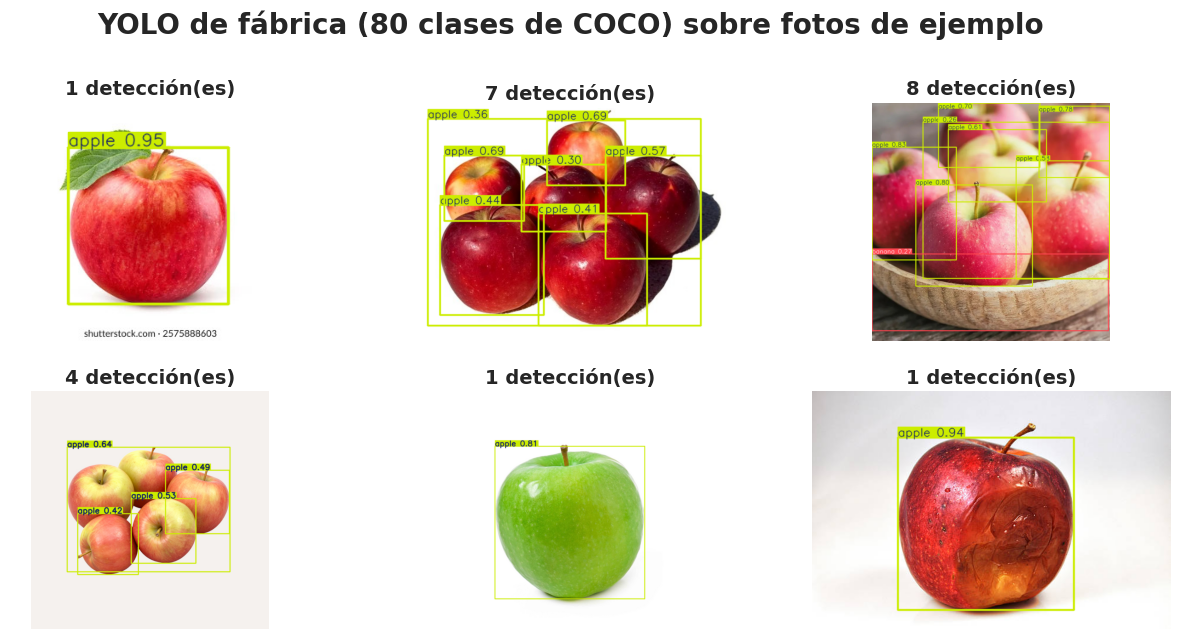

Gráfico guardado: f01_yolo_de_fabrica.png
Resultados guardados en: /content/resultados_manzanas/fabrica


,imagen,detecciones,clases
0,Manzana 1.jpg,1,apple
1,Manzana 2.jpg,7,apple
2,Manzana 3.jpg,8,"apple, banana"
3,Manzana 4.jpg,4,apple
4,Manzana 5.jpg,1,apple
5,Manzana podrida 1.jpg,1,apple
6,Manzana podrida 2.jpg,2,"apple, donut"
7,Manzana podrida 3.jpg,1,donut
8,Manzana podrida 4.jpg,1,apple
9,Manzana podrida 5.jpg,1,apple


In [12]:
# ============================================================
# PARTE 2B · Probarlo con fotos
# ============================================================
CARPETA_EJEMPLOS = BASE / "ejemplos"
ZIP_EJEMPLOS = BASE / "ejemplos.zip"                    # sus fotos de manzanas (NO del dataset) comprimidas
if ZIP_EJEMPLOS.exists() and not CARPETA_EJEMPLOS.exists():
    with zipfile.ZipFile(ZIP_EJEMPLOS) as z:
        z.extractall(CARPETA_EJEMPLOS)
EJEMPLOS_PROPIOS = sorted(p for p in CARPETA_EJEMPLOS.rglob("*")
                          if p.suffix.lower() in EXTENSIONES and "__MACOSX" not in str(p)) if CARPETA_EJEMPLOS.exists() else []
if EJEMPLOS_PROPIOS:
    EJEMPLOS = EJEMPLOS_PROPIOS
else:                                                   # sin fotos propias: demostración con dos fotos de Ultralytics
    print("AVISO: no hay ejemplos/ ni ejemplos.zip. Esta parte usa 2 fotos de Ultralytics solo para la demostración.")
    carpeta_demo = BASE / "ejemplos_demo"
    carpeta_demo.mkdir(exist_ok=True)
    for archivo in ["bus.jpg", "zidane.jpg"]:
        if not (carpeta_demo / archivo).exists():
            urllib.request.urlretrieve(f"https://ultralytics.com/images/{archivo}", carpeta_demo / archivo)
    EJEMPLOS = listar_imagenes(carpeta_demo)
print("Fotos de ejemplo:", [p.name for p in EJEMPLOS])

tabla_fabrica = predecir_imagenes(PARAMETROS["modelo_base"], EJEMPLOS, RESULTADOS / "fabrica",
                                  "YOLO de fábrica (80 clases de COCO) sobre fotos de ejemplo",
                                  "f01_yolo_de_fabrica.png")
tabla_fabrica

---
# Parte 3 · El dataset: imágenes, cajas y el archivo YAML

Para distinguir manzanas buenas de dañadas, YOLO necesita **imágenes** y, para cada una, **dónde está cada manzana y de qué clase es**. En formato YOLO eso son tres cosas:

1. Una carpeta `images/` con las fotos, separada en `train`, `val` y `test`.
2. Una carpeta `labels/` con **un archivo `.txt` por foto**. Cada línea es una caja: `clase x_centro y_centro ancho alto`, todo dividido por el tamaño de la imagen (números entre 0 y 1).
3. Un archivo **`data.yaml`** con las rutas y los nombres de las clases (`apple`, `damaged_apple`).

Usamos el dataset **Apple Sorting, versión 2** (Roboflow Universe), cuyo ZIP (formato YOLO, descargado de Roboflow Universe) la celda 3A **lee desde la carpeta `yolo_manzanas` de Google Drive** (ver Parte 0). Según la revisión del enunciado trae unas 697 imágenes repartidas en Train / Validation / Test (489 / 178 / 30): **comprueben esas cifras en la salida de la celda 3B**.

**Fuga de datos.** Si esta versión trae copias aumentadas de una misma foto, **no se juntan ni se vuelven a repartir**: la celda 3B conserva la partición original y la celda 3C **comprueba** que no haya fotos compartidas entre Train, Validation y Test.

**Test es chico (unas 30 imágenes):** sus métricas serán ruidosas. Hay que decirlo en el informe y no sacar conclusiones fuertes de diferencias pequeñas.

In [13]:
# ============================================================
# PARTE 3A · El dataset: su ZIP de Roboflow (viene de Google Drive)
# ============================================================
# El ZIP lo copió la celda 0C desde la carpeta yolo_manzanas de Drive.
ZIP_DATOS = ZIP_DATASET_LOCAL if ZIP_DATASET_LOCAL is not None else Path(PARAMETROS["dataset_zip"])
if not ZIP_DATOS.exists() and Path("/content").exists():   # respaldo: selector de archivos de Colab
    from google.colab import files
    print("No encontré el ZIP en Drive. Elige el ZIP del dataset (Roboflow → Download Dataset → YOLO) en tu computador...")
    ZIP_DATOS = BASE / next(iter(files.upload()))
ORIGEN = descomprimir_dataset(ZIP_DATOS, BASE / "datos_zip")
for carpeta in sorted(p for p in ORIGEN.rglob("*") if p.is_dir()):
    n = len(list(carpeta.glob("*.*")))
    if n:
        print(f"  {carpeta.relative_to(ORIGEN)}: {n} archivos")

Dataset descomprimido en: /content/datos_zip
  train: 489 imágenes
  val: 178 imágenes
  test: 30 imágenes
  test/images: 30 archivos
  test/labels: 30 archivos
  train/images: 489 archivos
  train/labels: 489 archivos
  valid/images: 178 archivos
  valid/labels: 178 archivos


In [14]:
# ============================================================
# PARTE 3B · Train, Validation y Test + data.yaml (sin volver a repartir)
# ============================================================
NOMBRES = leer_nombres(ORIGEN / "data.yaml")               # las clases salen del data.yaml del ZIP
print("Clases del ZIP:", NOMBRES)
if PARAMETROS["clases"]:                                   # nos quedamos solo con las clases elegidas
    filtrar_clases(ORIGEN, BASE / "datos_filtrados", PARAMETROS["clases"])
    ORIGEN, NOMBRES = BASE / "datos_filtrados", dict(enumerate(PARAMETROS["clases"]))
for s in ("train", "val", "test"):
    if buscar_split(ORIGEN, s)[0] is None:
        print(f"AVISO: la versión no trae '{s}'. crear_dataset_de_trabajo lo creará con semilla {SEMILLA}: explíquenlo en el informe.")
DATA_YAML = crear_dataset_de_trabajo(ORIGEN, DATOS, NOMBRES, PARAMETROS["fraccion_test"], SEMILLA)
print("\nContenido de data.yaml:\n")
print(DATA_YAML.read_text(encoding="utf-8"))

conteo = contar_dataset(DATOS, NOMBRES)
NUMEROS["conteo"] = conteo.to_dict()
conteo

Clases del ZIP: {0: 'apple', 1: 'damaged_apple'}
Dataset filtrado en: /content/datos_filtrados
       Imágenes  Cajas  Imágenes sin objetos  apple  damaged_apple
Split                                                             
train       489   1980                     1   1483            497
val         178    723                     0    522            201
test         30    157                     0    147             10
El dataset ya trae train, val y test: se conservan.
Dataset de trabajo en: /content/datos_manzanas

Contenido de data.yaml:

path: /content/datos_manzanas
train: images/train
val: images/val
test: images/test
names:
  0: apple
  1: damaged_apple



,Imágenes,Cajas,Imágenes sin objetos,apple,damaged_apple
Split,,,,,
train,489,1980,1,1483,497
val,178,723,0,522,201
test,30,157,0,147,10


In [15]:
# ============================================================
# PARTE 3C · ¿Hay fuga de datos? Copias de una misma foto entre splits
# ============================================================
por_split, cruces = revisar_fuga(DATOS)
display(por_split)
display(cruces)
NUMEROS["fuga"] = {"por_split": por_split.to_dict(), "cruces": cruces.to_dict()}
if cruces.values.sum() == 0:
    print("Sin fotos originales ni archivos idénticos compartidos entre splits.")
else:
    print("ATENCIÓN: hay fotos compartidas entre splits. Usen otra versión del dataset o una sin aumentos.")
print("Nota: esto detecta copias por nombre (.rf.) y por contenido idéntico; no detecta fotos distintas de una misma escena.")

,Imágenes,Fotos originales distintas,Copias aumentadas dentro del split,Archivos idénticos dentro del split
Split,,,,
train,489,489,0,0
val,178,178,0,0
test,30,30,0,0


,Fotos originales compartidas,Archivos idénticos compartidos
Par,,
train ↔ val,0,0
train ↔ test,0,0
val ↔ test,0,0


Sin fotos originales ni archivos idénticos compartidos entre splits.
Nota: esto detecta copias por nombre (.rf.) y por contenido idéntico; no detecta fotos distintas de una misma escena.


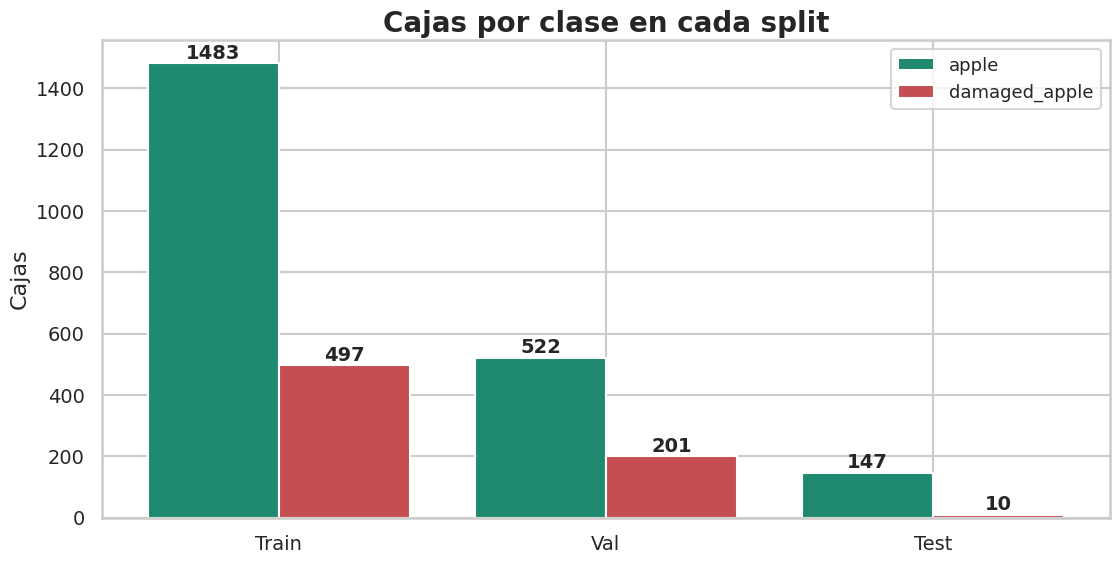

Gráfico guardado: f02_cajas_por_clase.png
Tamaño de las cajas, en % del área de la imagen:


,cajas,minimo,mediana,maximo
clase,,,,
apple,2152,0.01,3.36,78.39
damaged_apple,708,0.65,7.70,65.78


In [16]:
# ============================================================
# PARTE 3D · Cuántas cajas hay por clase y qué tan grandes son
# ============================================================
graficar_distribucion(conteo, NOMBRES, "f02_cajas_por_clase.png")
tabla_tamanos = tamano_cajas(DATOS, NOMBRES)
NUMEROS["tamano_cajas_pct_imagen"] = tabla_tamanos.to_dict()
print("Tamaño de las cajas, en % del área de la imagen:")
tabla_tamanos

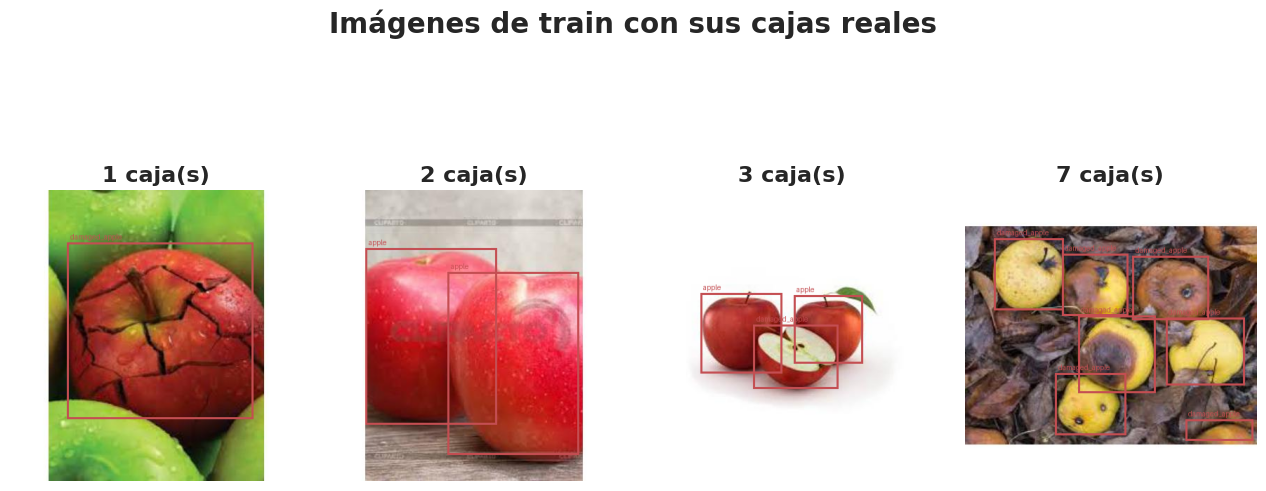

Gráfico guardado: f03_muestras_con_cajas.png


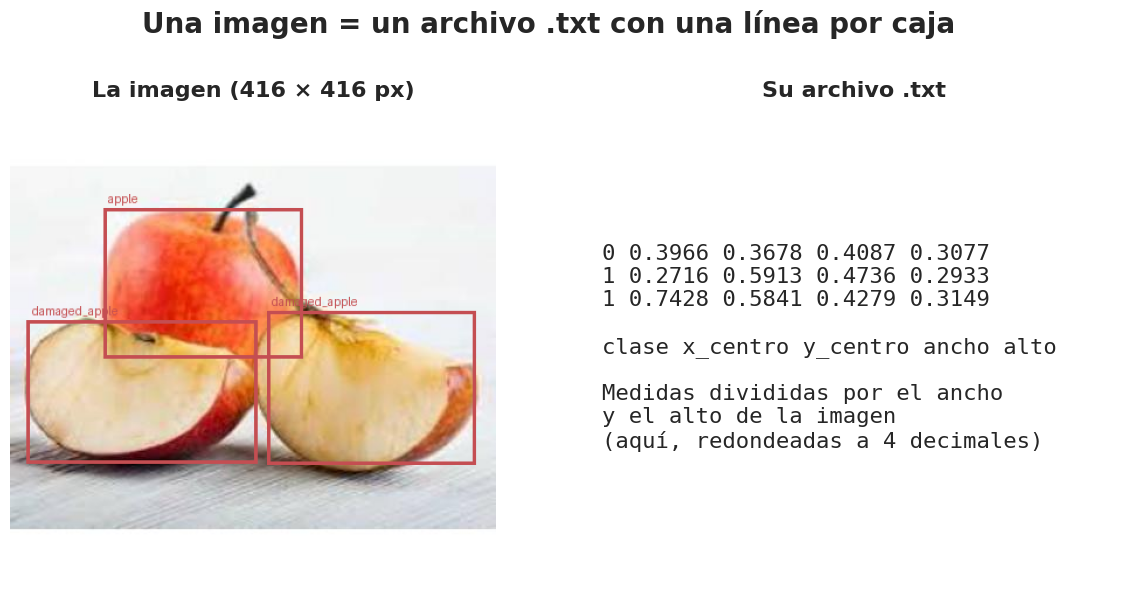

Gráfico guardado: f04_una_etiqueta_yolo.png


In [17]:
# ============================================================
# PARTE 3E · Ver las cajas: así se ve una etiqueta
# ============================================================
mostrar_muestras(DATOS, "train", NOMBRES, n=4, nombre="f03_muestras_con_cajas.png")
ruta_ejemplo, lineas_ejemplo = explicar_etiqueta(DATOS, "train", NOMBRES, nombre="f04_una_etiqueta_yolo.png")
NUMEROS["etiqueta_ejemplo"] = {"imagen": ruta_ejemplo.name, "lineas": lineas_ejemplo}

---
# Parte 4 · Transfer learning

Igual que en la clase 09: partimos de un modelo que ya sabe ver (YOLO26n preentrenado con COCO) y **congelamos el backbone** (`freeze=10`), las primeras capas que detectan bordes, texturas y formas. Solo se entrenan las capas finales, que aprenden a separar `apple` de `damaged_apple`.

Con un dataset chico usamos **todo el Train** (`fraccion_transfer = 1.0`).

**Paciencia:** si durante 10 épocas seguidas el modelo no mejora en Validation, el entrenamiento se detiene y se queda con la mejor época. Seguir ahí solo sobreajusta (la pérdida de Train baja y la de Validation sube).

Ultralytics guarda todo en `runs_manzanas/transfer_learning/`: los pesos (`weights/best.pt`), las métricas por época (`results.csv`) y sus gráficos.

In [18]:
# ============================================================
# PARTE 4A · Entrenamiento con el backbone congelado
# ============================================================
RUTA_TL, SEGUNDOS_TL, RUN_TL = entrenar(
    PARAMETROS["modelo_base"],                 # 1) partimos de los pesos de COCO
    "transfer_learning",
    epocas=PARAMETROS["epocas_transfer"],      # 2) pocas épocas
    fraccion=PARAMETROS["fraccion_transfer"],  # 3) una parte del Train
    congelar=PARAMETROS["capas_congeladas"],   # 4) backbone congelado
    horas=PARAMETROS["horas_maximas_transfer"],
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos_manzanas/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=transfer_learning, nbs=64, nms=None, opset=None, optimize=F

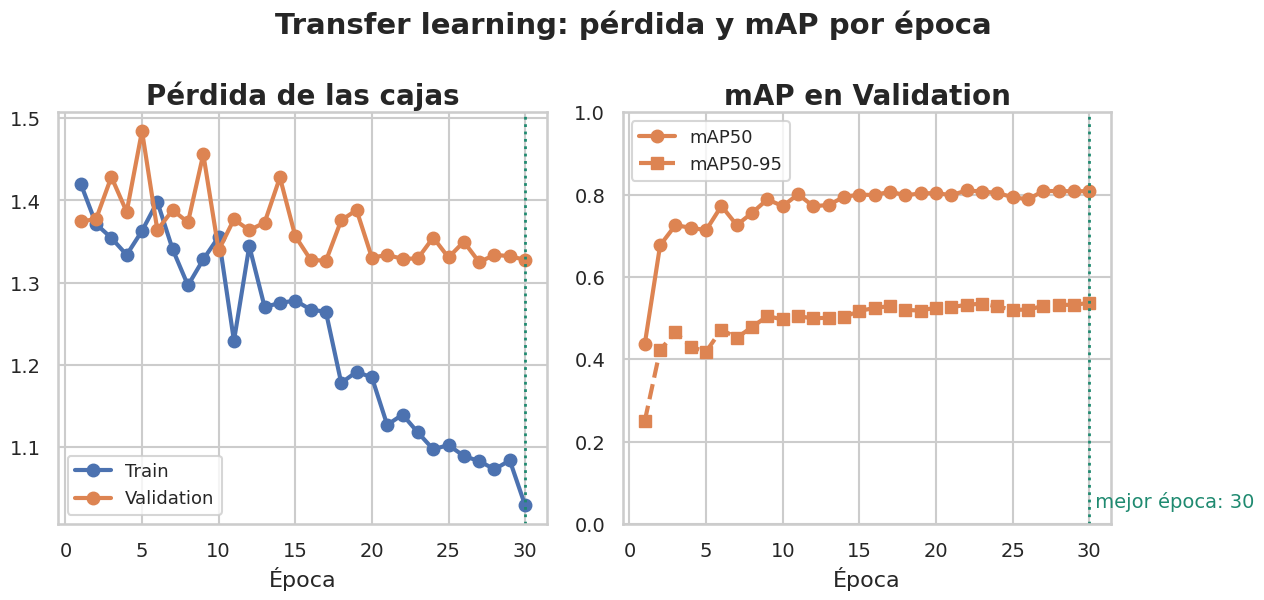

Gráfico guardado: f05_curvas_transfer.png
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 819.1±215.2 MB/s, size: 18.4 KB)
val: Scanning /content/datos_manzanas/labels/val.cache... 178 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 178/178 62.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 4.2it/s 2.9s
                   all        178        723       0.74      0.801      0.809      0.537
Speed: 1.8ms preprocess, 4.7ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs_manzanas/eval_transfer_learning_val
transfer_learning en val: {'Precision': 0.74, 'Recall': 0.801, 'mAP50': 0.809, 'mAP50-95': 0.537}


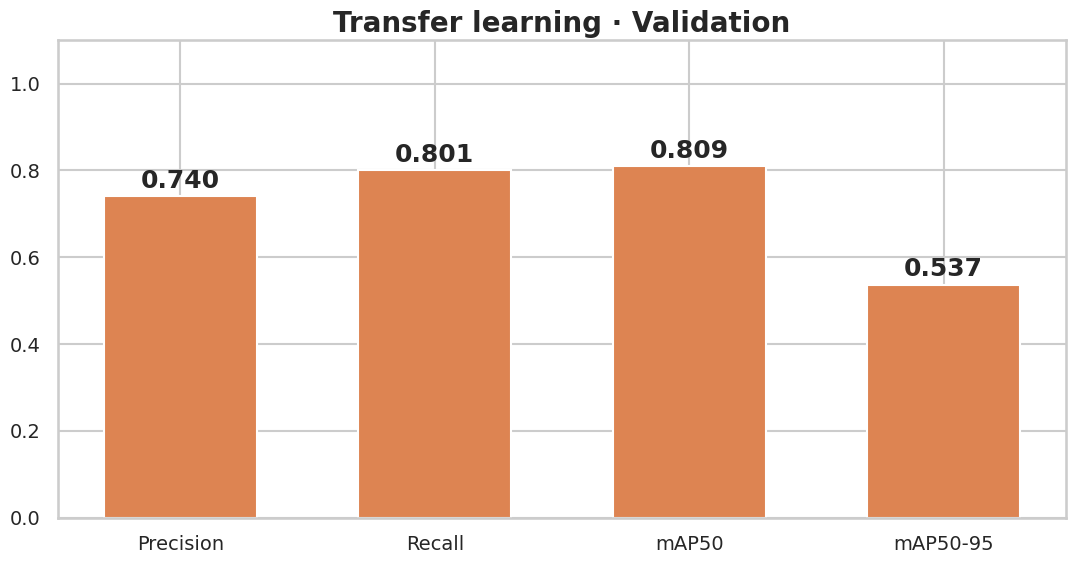

Gráfico guardado: f06_metricas_transfer_val.png


In [19]:
# ============================================================
# PARTE 4B · Curvas y métricas en Validation
# ============================================================
MEJOR_EPOCA_TL, EPOCAS_TL = graficar_curvas(RUN_TL, "Transfer learning: pérdida y mAP por época", "f05_curvas_transfer.png")
METRICAS_TL, EVAL_TL = evaluar(RUTA_TL, "val", "transfer_learning")
graficar_metricas(METRICAS_TL, "Transfer learning · Validation", "f06_metricas_transfer_val.png")
NUMEROS["transfer_learning"] = {"minutos": SEGUNDOS_TL / 60, "epocas": EPOCAS_TL,
                                "mejor_epoca": MEJOR_EPOCA_TL, "validation": METRICAS_TL}

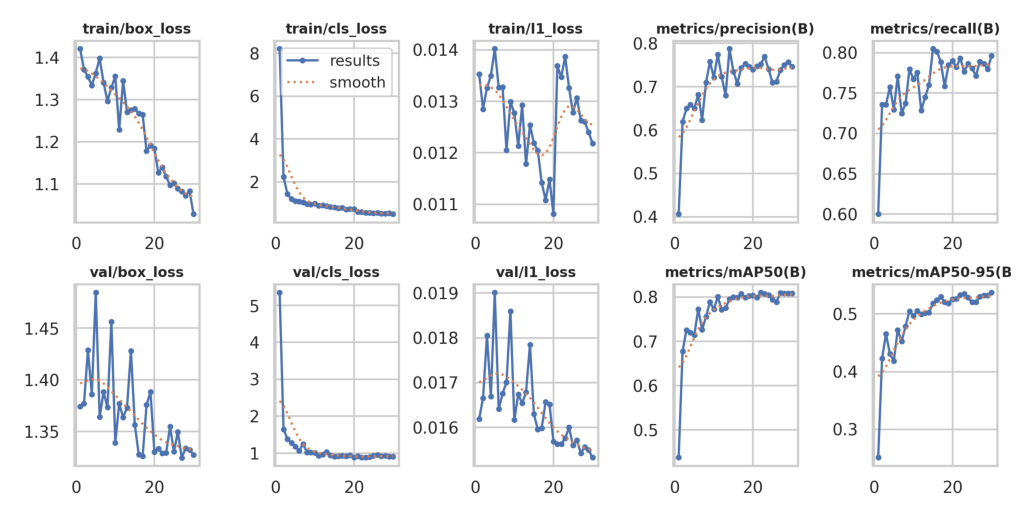

Gráfico guardado: f07_results_ultralytics_tl.png


In [20]:
# ============================================================
# PARTE 4C · El resumen que arma Ultralytics
# ============================================================
copiar_figura(RUN_TL / "results.png", "f07_results_ultralytics_tl.png")

,Precision,Recall,mAP50,mAP50-95
apple,0.770,0.820,0.827,0.488
damaged_apple,0.711,0.781,0.791,0.585


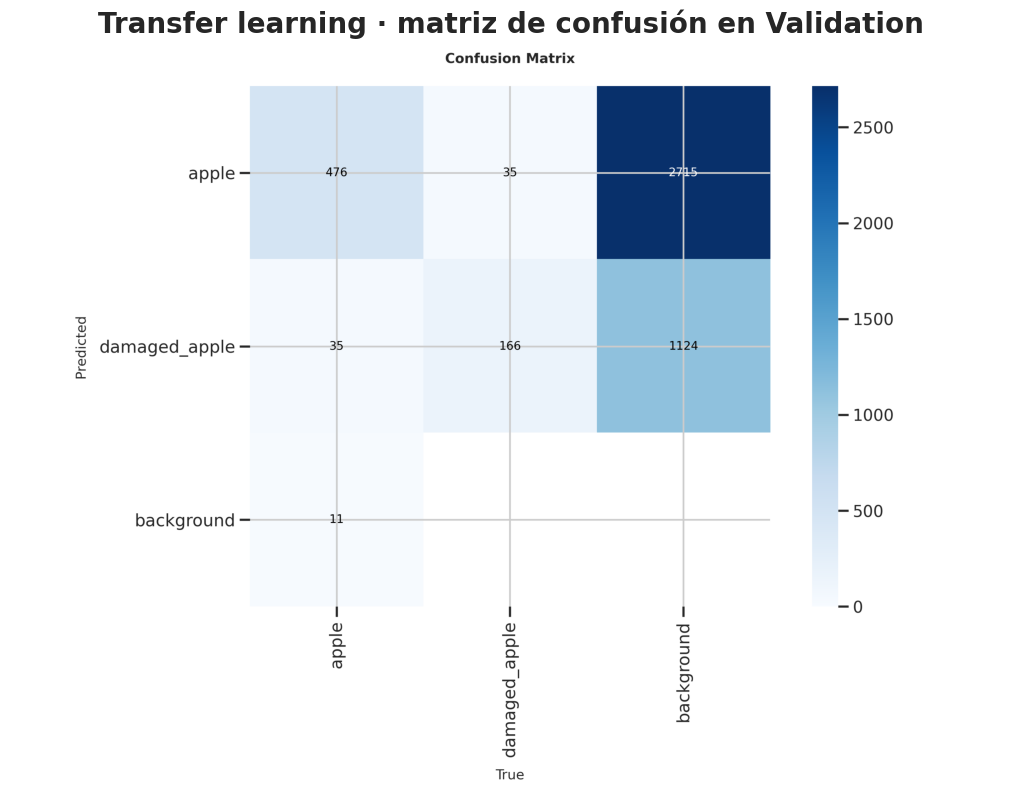

Gráfico guardado: f08_confusion_transfer_val.png


In [21]:
# ============================================================
# PARTE 4D · Por clase y matriz de confusión del transfer learning (Validation)
# ============================================================
display(pd.DataFrame(POR_CLASE["transfer_learning_val"]).T.round(3))
copiar_figura(EVAL_TL / "confusion_matrix.png", "f08_confusion_transfer_val.png",
              "Transfer learning · matriz de confusión en Validation")

---
# Parte 5 · ¿Cómo se mide un detector?

En clasificación bastaba comparar la clase predicha con la real. En detección también importa **dónde** quedó la caja.

- **IoU** (*Intersection over Union*): cuánto se superpone la caja predicha con la real. 1 es perfecta y 0, que no se tocan. Una detección cuenta como **acierto** si su IoU llega a un umbral, normalmente **0,5**.
- **Precision**: de todas las cajas que dibujó el modelo, qué parte era una manzana de esa clase de verdad. Baja cuando inventa manzanas o las etiqueta mal (por ejemplo, llama «dañada» a una sana).
- **Recall**: de todas las manzanas reales, qué parte encontró. Baja cuando se le escapan manzanas, o cuando las ve pero les pone la clase equivocada.
- Las dos dependen de la **confianza mínima**: si se exige más, el modelo inventa menos (sube precision), pero se le escapan más (baja recall).
- **mAP50**: resume precision y recall en todos los niveles de confianza, con IoU de 0,5. **mAP50-95**: lo mismo, exigiendo cajas cada vez más ajustadas (IoU de 0,50 a 0,95); siempre es menor.
- **Por clase:** aquí importa mirar `apple` y `damaged_apple` por separado. El promedio puede esconder que una clase (normalmente la minoritaria) rinde mucho peor.
- **Matriz de confusión:** muestra cuántas manzanas de cada clase real se detectaron como cada clase, y cuántas se perdieron (*background*).

Ojo: la precision y el recall que reporta Ultralytics están calculados en la confianza que da el mejor equilibrio entre ambos. Por eso no coinciden con el conteo de la Parte 5B, que usa la confianza mínima de 0,25 con que se dibujan las cajas.

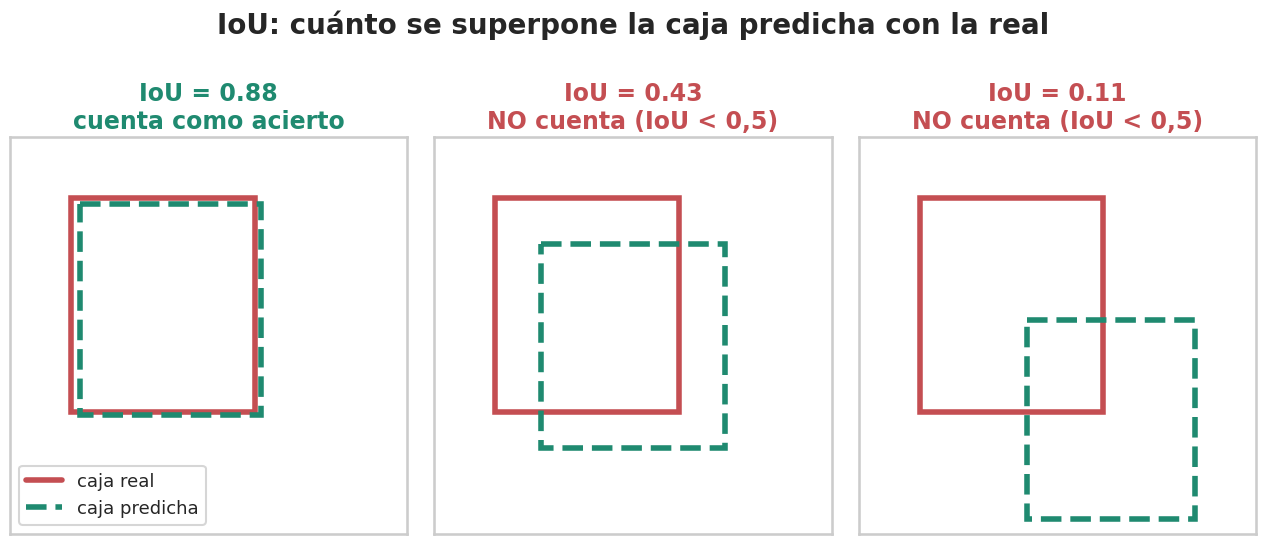

Gráfico guardado: f09_iou.png


In [22]:
# ============================================================
# PARTE 5A · IoU en un dibujo
# ============================================================
graficar_iou("f09_iou.png")

{'Aciertos': 580, 'Falsas detecciones': 224, 'Objetos perdidos': 143, 'Precision': 0.721, 'Recall': 0.802, 'Imágenes': 178}


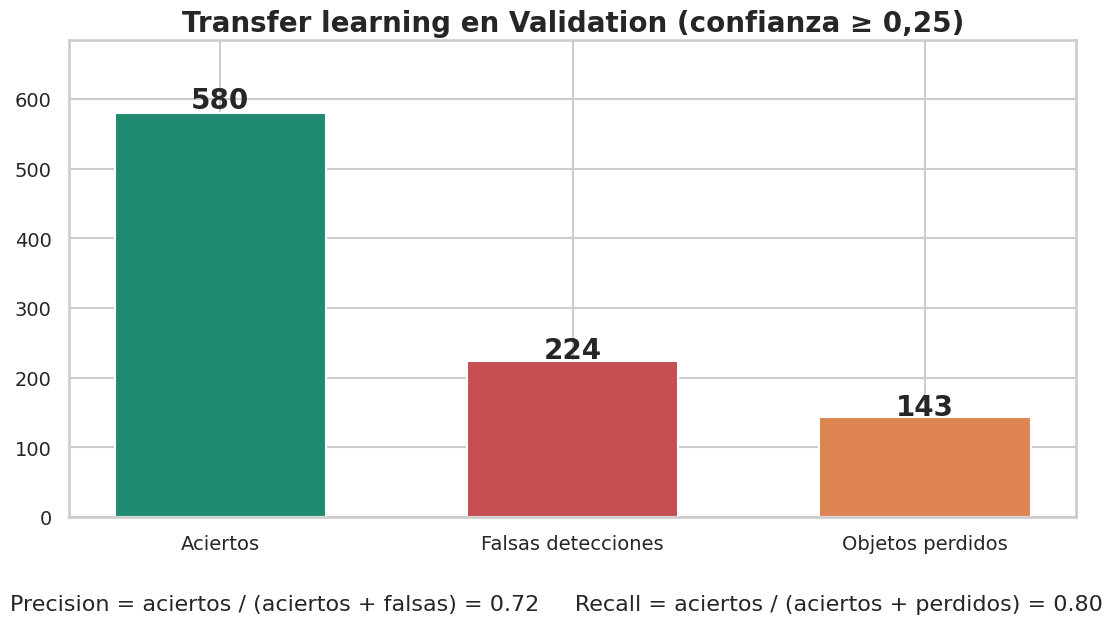

Gráfico guardado: f10_aciertos_transfer_val.png


In [23]:
# ============================================================
# PARTE 5B · Aciertos, falsas detecciones y manzanas perdidas (con confianza 0,25)
# ============================================================
ACIERTOS_TL = contar_aciertos(RUTA_TL, DATOS, "val", NOMBRES, conf=PARAMETROS["confianza"])
graficar_aciertos(ACIERTOS_TL, "Transfer learning en Validation (confianza ≥ 0,25)", "f10_aciertos_transfer_val.png")
NUMEROS["transfer_learning"]["aciertos_val"] = ACIERTOS_TL

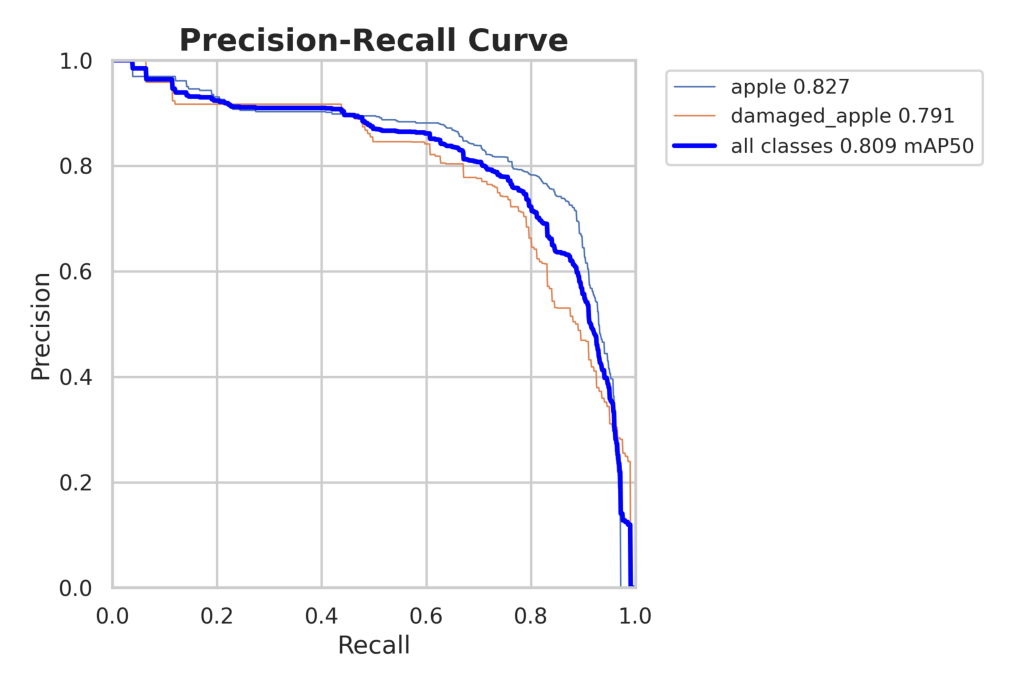

Gráfico guardado: f11_curva_pr_transfer.png


In [24]:
# ============================================================
# PARTE 5C · Curva precision-recall: qué pasa al mover la confianza mínima
# ============================================================
copiar_figura(EVAL_TL / "BoxPR_curve.png", "f11_curva_pr_transfer.png")

---
# Parte 6 · Fine tuning

Ahora **descongelamos todo** y seguimos entrenando desde el `best.pt` del transfer learning, con **AdamW** y un **learning rate bajo** (`1e-4`) para ajustar sin romper lo aprendido.

In [25]:
# ============================================================
# PARTE 6A · Entrenamiento con todas las capas
# ============================================================
RUTA_FT, SEGUNDOS_FT, RUN_FT = entrenar(
    RUTA_TL,                                      # 1) partimos del mejor modelo anterior
    "fine_tuning",
    epocas=PARAMETROS["epocas_fine_tuning"],
    fraccion=PARAMETROS["fraccion_fine_tuning"],
    congelar=None,                                # 2) nada congelado
    optimizador="AdamW",                          # 3) optimizador explícito para que respete lr0
    lr0=PARAMETROS["lr_fine_tuning"],             # 4) learning rate bajo
    horas=PARAMETROS["horas_maximas_fine_tuning"],
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos_manzanas/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs_manzanas/transfer_learning/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fine_tuni

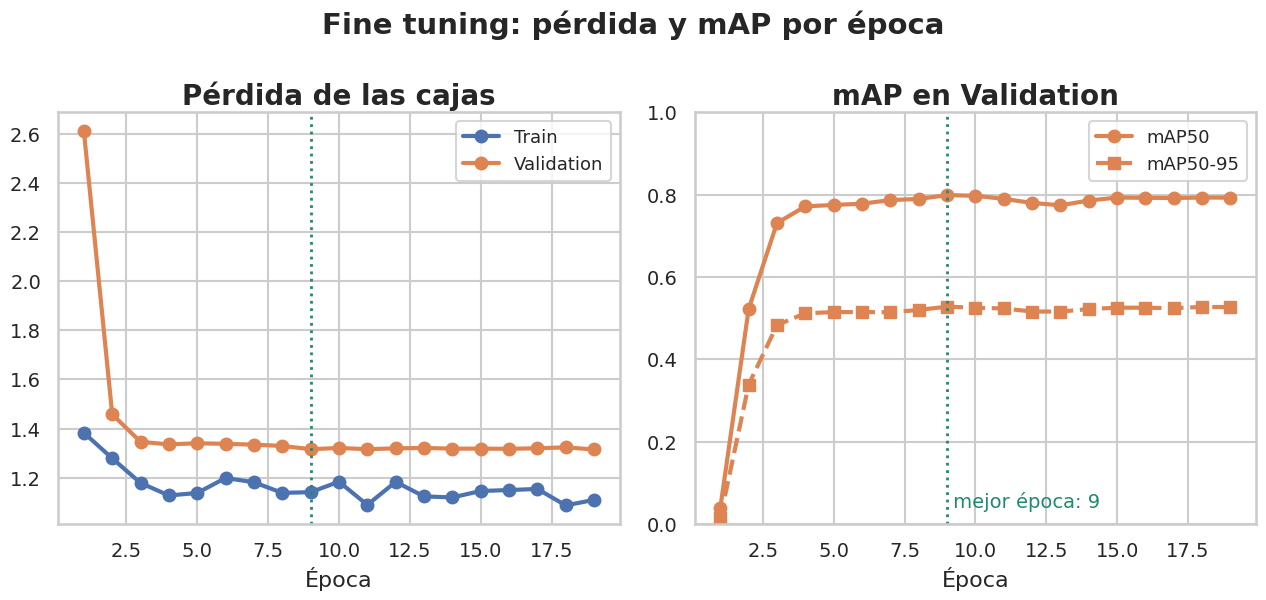

Gráfico guardado: f12_curvas_fine_tuning.png
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 568.6±248.5 MB/s, size: 18.4 KB)
val: Scanning /content/datos_manzanas/labels/val.cache... 178 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 178/178 46.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.4it/s 3.6s
                   all        178        723      0.766      0.733      0.799      0.528
Speed: 2.9ms preprocess, 5.1ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs_manzanas/eval_fine_tuning_val
fine_tuning en val: {'Precision': 0.766, 'Recall': 0.733, 'mAP50': 0.799, 'mAP50-95': 0.528}


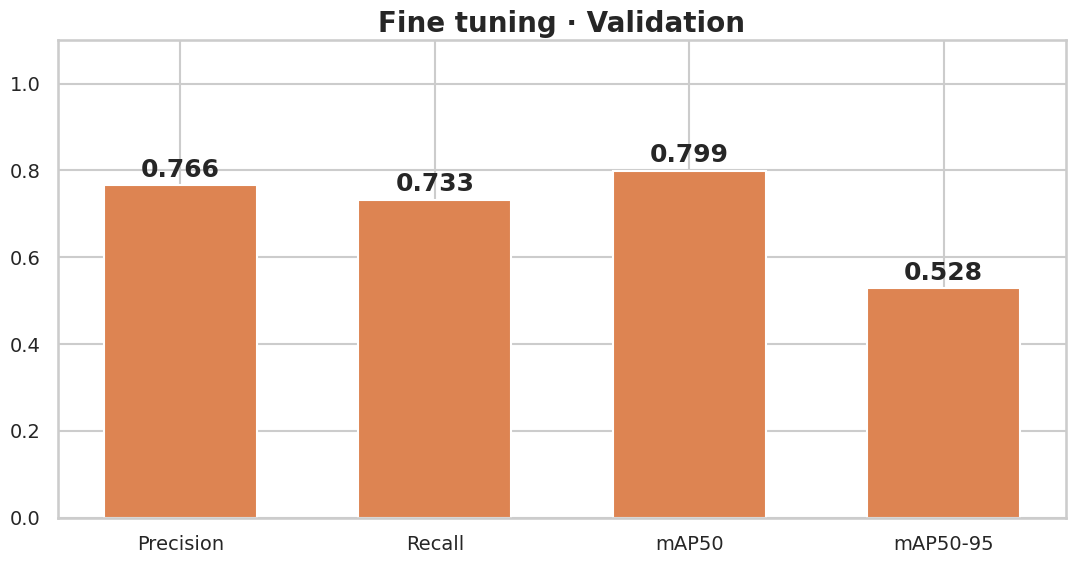

Gráfico guardado: f13_metricas_fine_tuning_val.png


In [26]:
# ============================================================
# PARTE 6B · Curvas y métricas en Validation
# ============================================================
MEJOR_EPOCA_FT, EPOCAS_FT = graficar_curvas(RUN_FT, "Fine tuning: pérdida y mAP por época", "f12_curvas_fine_tuning.png")
METRICAS_FT, EVAL_FT = evaluar(RUTA_FT, "val", "fine_tuning")
graficar_metricas(METRICAS_FT, "Fine tuning · Validation", "f13_metricas_fine_tuning_val.png")
NUMEROS["fine_tuning"] = {"minutos": SEGUNDOS_FT / 60, "epocas": EPOCAS_FT,
                          "mejor_epoca": MEJOR_EPOCA_FT, "validation": METRICAS_FT}

{'Aciertos': 582, 'Falsas detecciones': 245, 'Objetos perdidos': 141, 'Precision': 0.704, 'Recall': 0.805, 'Imágenes': 178}


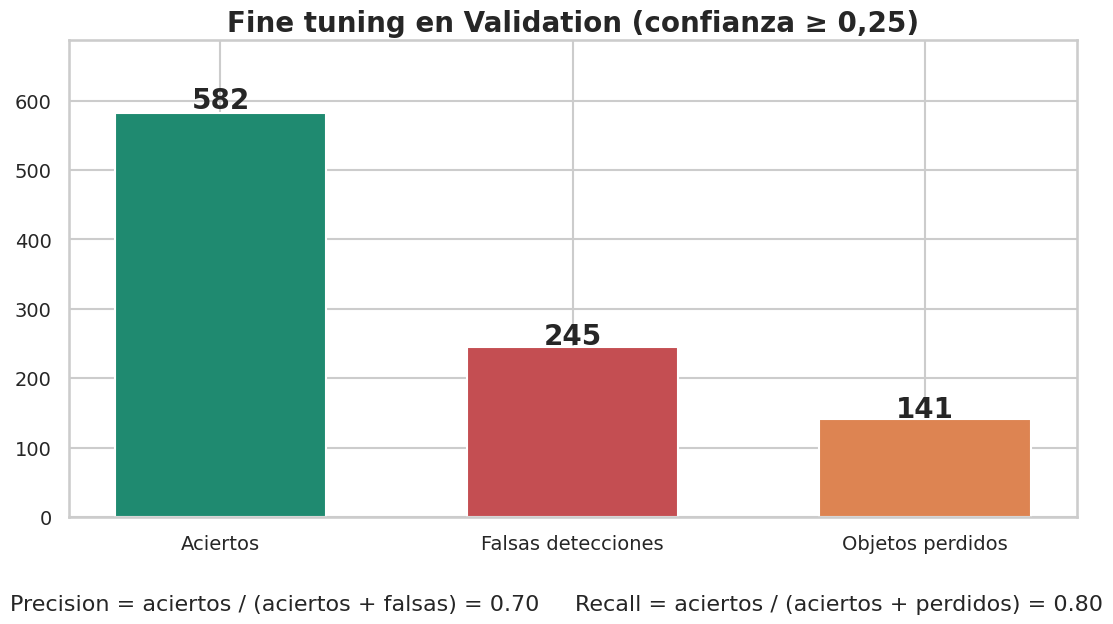

Gráfico guardado: f14_aciertos_fine_tuning_val.png


,Precision,Recall,mAP50,mAP50-95
apple,0.801,0.764,0.808,0.471
damaged_apple,0.731,0.701,0.790,0.586


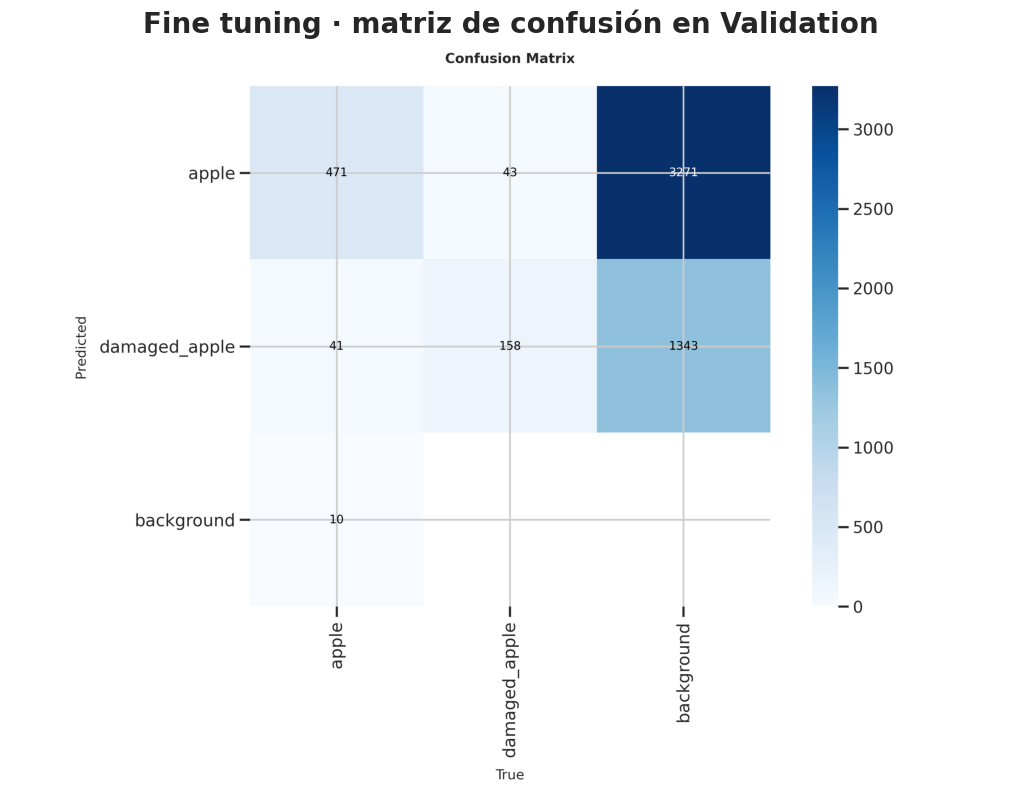

Gráfico guardado: f15_confusion_fine_tuning_val.png


In [27]:
# ============================================================
# PARTE 6C · Aciertos, por clase y matriz de confusión del fine tuning (Validation)
# ============================================================
ACIERTOS_FT = contar_aciertos(RUTA_FT, DATOS, "val", NOMBRES, conf=PARAMETROS["confianza"])
graficar_aciertos(ACIERTOS_FT, "Fine tuning en Validation (confianza ≥ 0,25)", "f14_aciertos_fine_tuning_val.png")
NUMEROS["fine_tuning"]["aciertos_val"] = ACIERTOS_FT
display(pd.DataFrame(POR_CLASE["fine_tuning_val"]).T.round(3))
copiar_figura(EVAL_FT / "confusion_matrix.png", "f15_confusion_fine_tuning_val.png",
              "Fine tuning · matriz de confusión en Validation")

In [28]:
# ============================================================
# PARTE 6D · Configuración declarada de los dos entrenamientos
# ============================================================
TABLA_CONFIG = pd.DataFrame({
    "Transfer learning": {
        "Modelo base": PARAMETROS["modelo_base"] + " (COCO)",
        "Épocas pedidas / ejecutadas": f"{PARAMETROS['epocas_transfer']} / {EPOCAS_TL}",
        "Mejor época": MEJOR_EPOCA_TL,
        "Tamaño de imagen (px)": PARAMETROS["imgsz"],
        "Fracción del Train": PARAMETROS["fraccion_transfer"],
        "Capas congeladas": PARAMETROS["capas_congeladas"],
        "Optimizador / learning rate": "auto (lo elige Ultralytics)",
        "GPU": NOMBRE_GPU,
        "Duración (min)": round(SEGUNDOS_TL / 60, 1),
    },
    "Fine tuning": {
        "Modelo base": "best.pt del transfer learning",
        "Épocas pedidas / ejecutadas": f"{PARAMETROS['epocas_fine_tuning']} / {EPOCAS_FT}",
        "Mejor época": MEJOR_EPOCA_FT,
        "Tamaño de imagen (px)": PARAMETROS["imgsz"],
        "Fracción del Train": PARAMETROS["fraccion_fine_tuning"],
        "Capas congeladas": "ninguna",
        "Optimizador / learning rate": f"AdamW / {PARAMETROS['lr_fine_tuning']}",
        "GPU": NOMBRE_GPU,
        "Duración (min)": round(SEGUNDOS_FT / 60, 1),
    },
})
NUMEROS["configuracion"] = TABLA_CONFIG.to_dict()
TABLA_CONFIG

,Transfer learning,Fine tuning
Modelo base,yolo26n.pt (COCO),best.pt del transfer learning
Épocas pedidas / ejecutadas,30 / 30,30 / 19
Mejor época,30,9
Tamaño de imagen (px),640,640
Fracción del Train,1.0,1.0
Capas congeladas,10,ninguna
Optimizador / learning rate,auto (lo elige Ultralytics),AdamW / 0.0001
GPU,Tesla T4,Tesla T4
Duración (min),4.8,3.2


---
# Parte 7 · Comparar los modelos con Validation

**Regla de elección, escrita antes de mirar Test:** nos quedamos con el modelo de **mayor mAP50-95 en Validation**. Test no interviene en esta decisión.

,Precision,Recall,mAP50,mAP50-95
Transfer learning,0.740,0.801,0.809,0.537
Fine tuning,0.766,0.733,0.799,0.528


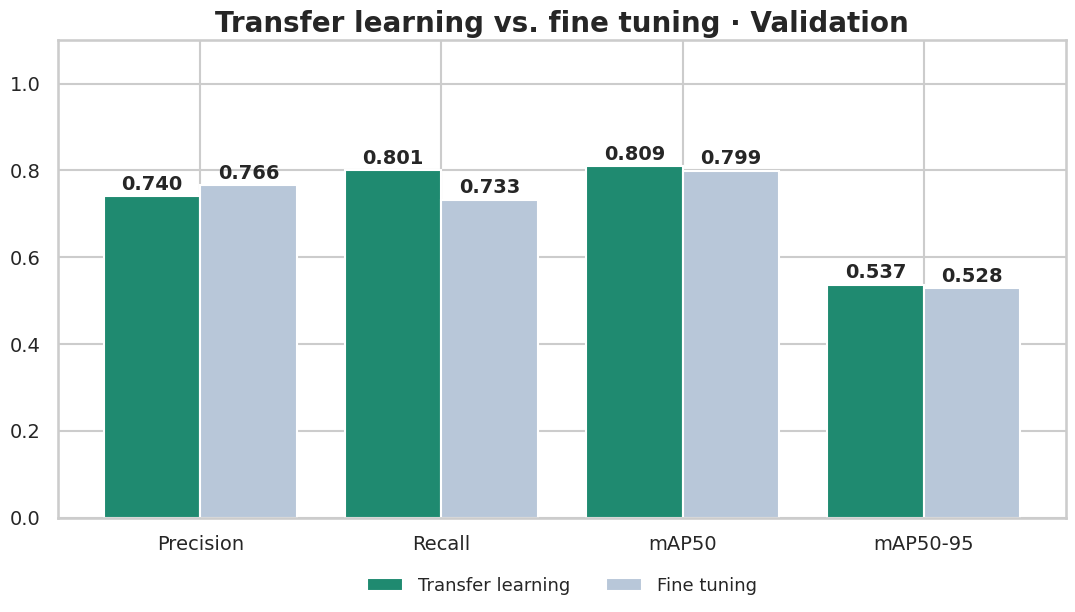

Gráfico guardado: f16_comparacion_validation.png
Modelo elegido: Transfer learning


In [29]:
# ============================================================
# PARTE 7A · Elegir con Validation
# ============================================================
CANDIDATOS = {"Transfer learning": (RUTA_TL, METRICAS_TL), "Fine tuning": (RUTA_FT, METRICAS_FT)}
TABLA_VAL = pd.DataFrame({k_: v[1] for k_, v in CANDIDATOS.items()}).T.round(3)
display(TABLA_VAL)
ELEGIDO = max(CANDIDATOS, key=lambda k_: CANDIDATOS[k_][1]["mAP50-95"])
RUTA_ELEGIDO = CANDIDATOS[ELEGIDO][0]
comparar_modelos({k_: v[1] for k_, v in CANDIDATOS.items()}, "Transfer learning vs. fine tuning · Validation",
                 "f16_comparacion_validation.png", elegido=ELEGIDO)
print("Modelo elegido:", ELEGIDO)
NUMEROS["elegido"] = ELEGIDO

---
# Parte 8 · Evaluación final con Test

Test se usa **una sola vez** para medir, con el modelo elegido y **al mismo tamaño de imagen del entrenamiento**: si se evalúa a otro tamaño, las métricas cambian. No se ajusta nada después de mirarlo.

**Cuidado al interpretar:** Test tiene muy pocas imágenes (unas 30), así que una sola manzana mal detectada mueve bastante las cifras. Comparen con Validation, pero eviten conclusiones fuertes.

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 634.9±193.3 MB/s, size: 21.0 KB)
val: Scanning /content/datos_manzanas/labels/test... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 1.6Kit/s 0.0s
val: New cache created: /content/datos_manzanas/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5it/s 1.3s
                   all         30        157      0.696      0.632      0.677      0.463
Speed: 4.3ms preprocess, 8.8ms inference, 0.0ms loss, 4.5ms postprocess per image
Results saved to /content/runs_manzanas/eval_elegido_test
elegido en test: {'Precision': 0.696, 'Recall': 0.632, 'mAP50': 0.677, 'mAP50-95': 0.463}


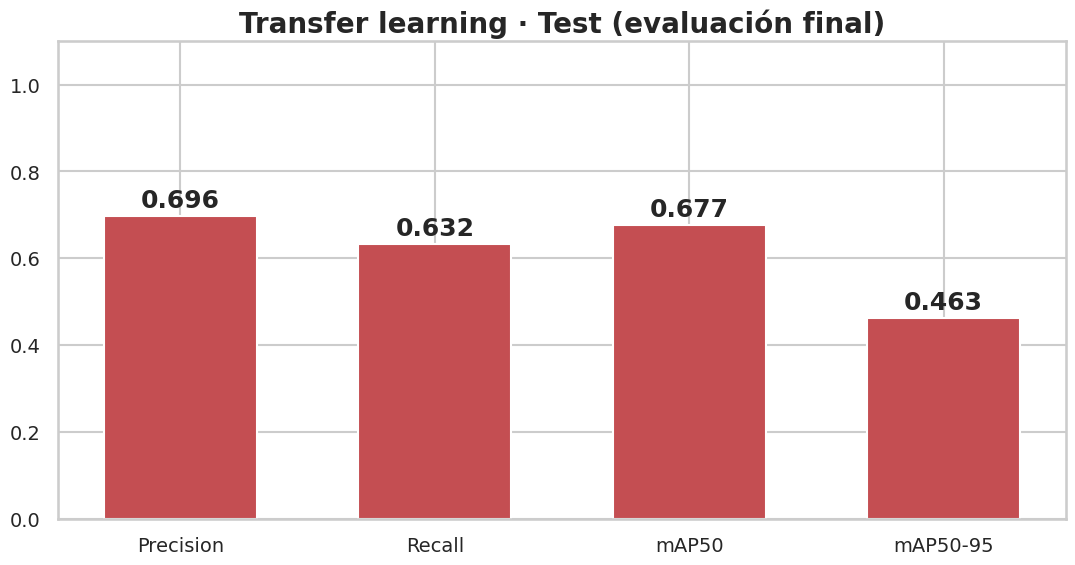

Gráfico guardado: f17_metricas_test.png


,Precision,Recall,mAP50,mAP50-95
apple,0.845,0.864,0.909,0.613
damaged_apple,0.548,0.400,0.445,0.312


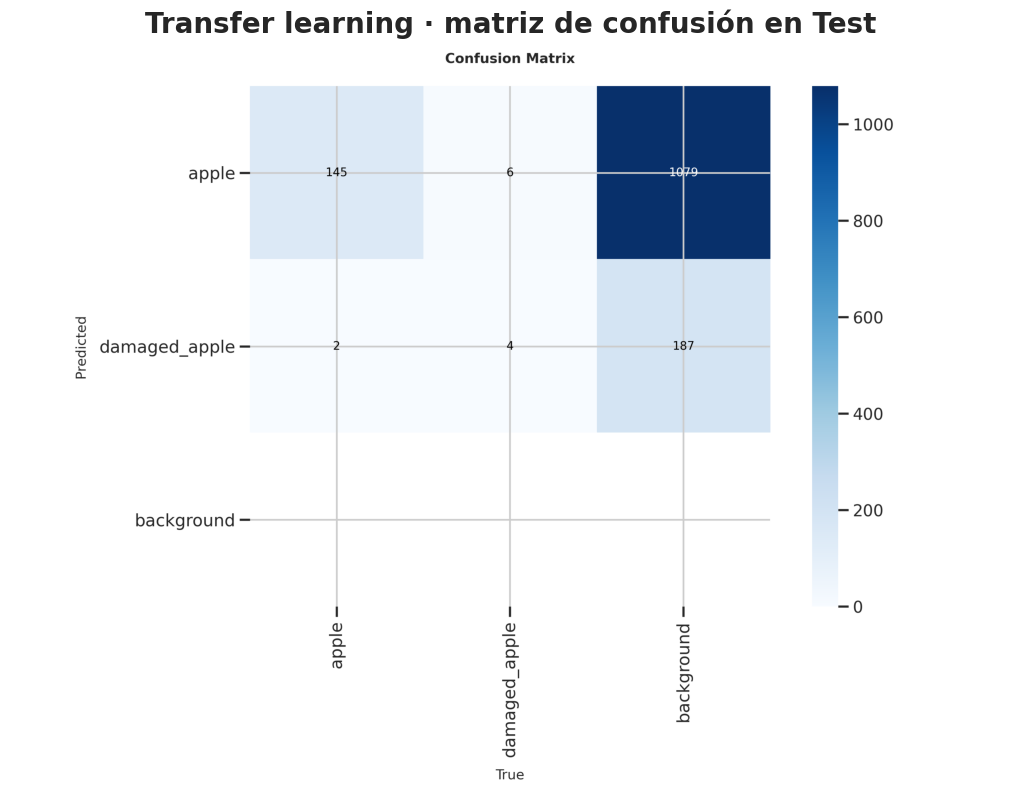

Gráfico guardado: f18_confusion_test.png


In [30]:
# ============================================================
# PARTE 8A · Métricas en Test (única evaluación) + por clase + matriz de confusión
# ============================================================
METRICAS_TEST, EVAL_TEST = evaluar(RUTA_ELEGIDO, "test", "elegido")
graficar_metricas(METRICAS_TEST, f"{ELEGIDO} · Test (evaluación final)", "f17_metricas_test.png", color=TEST)
NUMEROS["test"] = METRICAS_TEST
NUMEROS["test_por_clase"] = POR_CLASE["elegido_test"]
display(pd.DataFrame(POR_CLASE["elegido_test"]).T.round(3))
copiar_figura(EVAL_TEST / "confusion_matrix.png", "f18_confusion_test.png", f"{ELEGIDO} · matriz de confusión en Test")

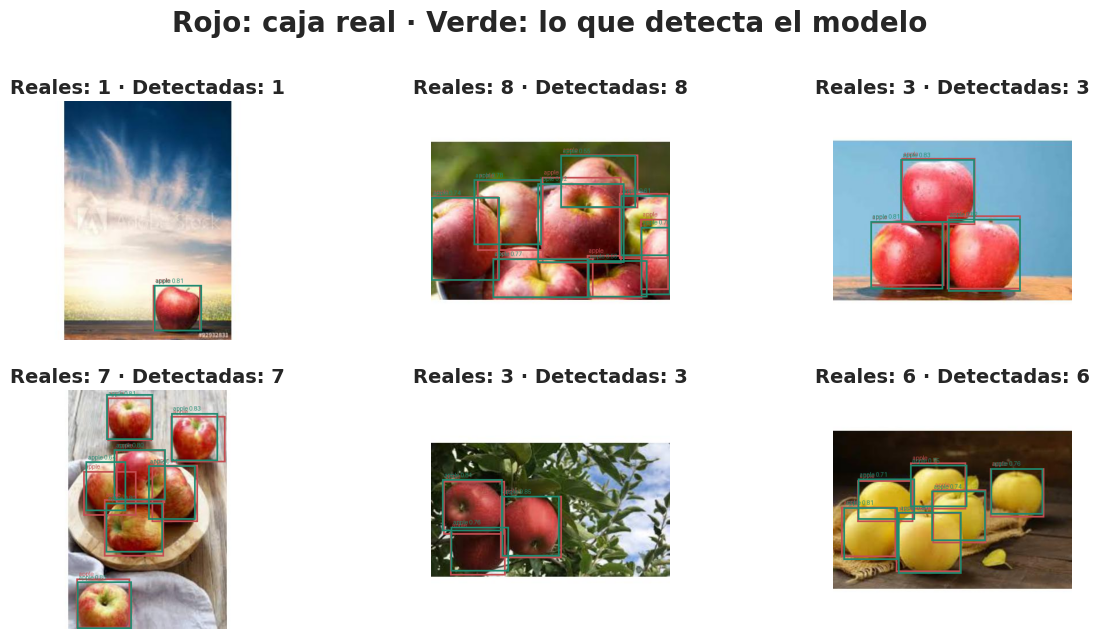

Gráfico guardado: f19_real_vs_detectado_test.png


In [31]:
# ============================================================
# PARTE 8B · Cajas reales vs. detectadas en Test
# ============================================================
galeria_real_vs_predicho(RUTA_ELEGIDO, DATOS, "test", NOMBRES, n=6, nombre="f19_real_vs_detectado_test.png")

Eventos en test (confianza ≥ 0.25): {'acierto': 134, 'perdida': 14, 'falsa': 24, 'mal_ubicada': 2, 'confundida': 7}


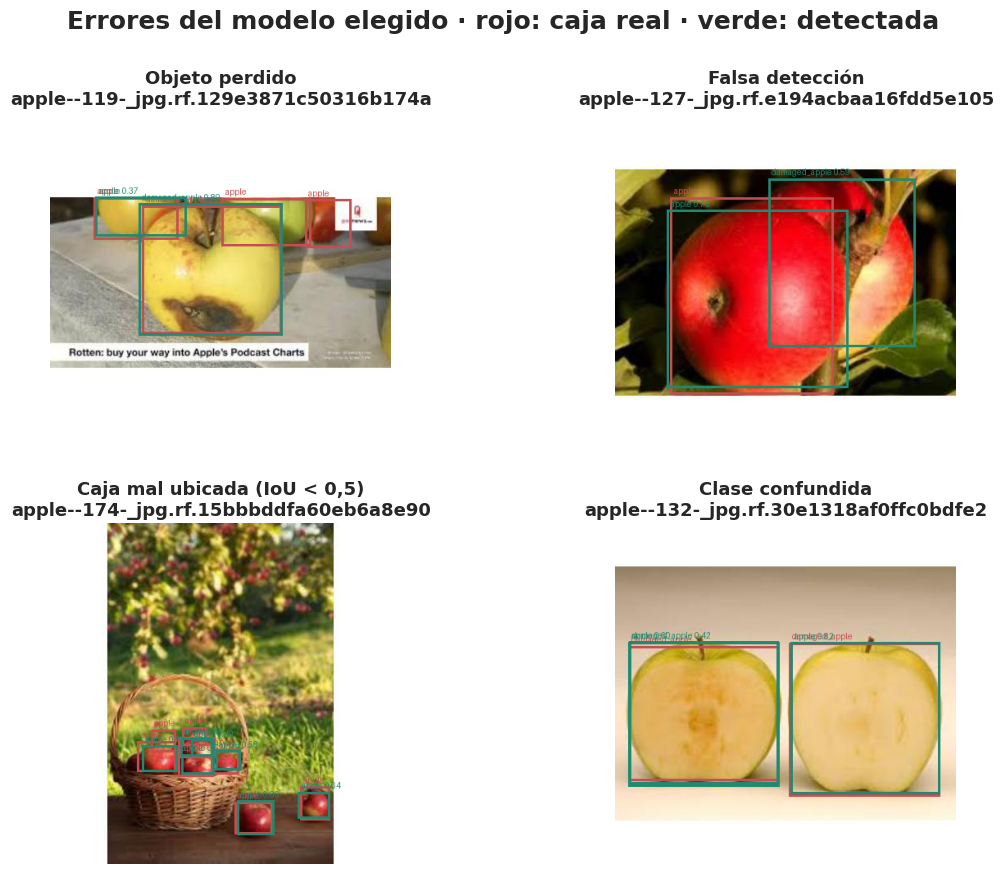

Gráfico guardado: f20_errores_test.png


{'falsa': 'apple--127-_jpg.rf.e194acbaa16fdd5e105c6ee60eaba4ed.jpg',
 'perdida': 'apple--119-_jpg.rf.129e3871c50316b174a5b44d44d04fdc.jpg',
 'confundida': 'apple--132-_jpg.rf.30e1318af0ffc0bdfe2423b39e4b5024.jpg',
 'mal_ubicada': 'apple--174-_jpg.rf.15bbbddfa60eb6a8e90e9781d2e6dc78.jpg'}

In [32]:
# ============================================================
# PARTE 8C · Los errores, uno por tipo (para comentarlos en el informe)
# ============================================================
# Muestra un ejemplo de: objeto perdido, falsa detección, caja mal ubicada y clase confundida.
# Es solo para mirar y explicar: no cambia métricas ni la elección del modelo.
CONTEO_ERRORES, ARCHIVOS_ERRORES = galeria_errores(RUTA_ELEGIDO, DATOS, "test", NOMBRES,
                                                   conf=PARAMETROS["confianza"], nombre="f20_errores_test.png")
NUMEROS["errores_test"] = {"conteo": CONTEO_ERRORES, "imagenes": ARCHIVOS_ERRORES}
ARCHIVOS_ERRORES

---
# Parte 9 · Usar el modelo con imágenes y con video

Entrenar necesita GPU; **usar** el modelo, no tanto. Aquí se prueba fuera del dataset (los archivos vienen de la carpeta `yolo_manzanas` de Google Drive, celda 0C):

- **Imágenes:** las fotos de `ejemplos/` (o `ejemplos.zip`): manzanas que **no** sean del dataset, con distinta luz, fondo, distancia y punto de vista. Los resultados quedan en `resultados_manzanas/imagenes/`.
- **Dos videos:** `video_prueba_1.mp4` y `video_prueba_2.mp4` junto al notebook (o dos `.mp4` en `ejemplos/`): cada uno de al menos 10 segundos y que no salga del dataset. Los videos con las cajas quedan en `resultados_manzanas/video_1_detectado.mp4` y `video_2_detectado.mp4`.

Si faltan fotos o videos propios, la celda lo avisa y usa imágenes de Test **solo para que el notebook corra**: eso no sirve como evidencia del informe ni para la Evaluación 04.

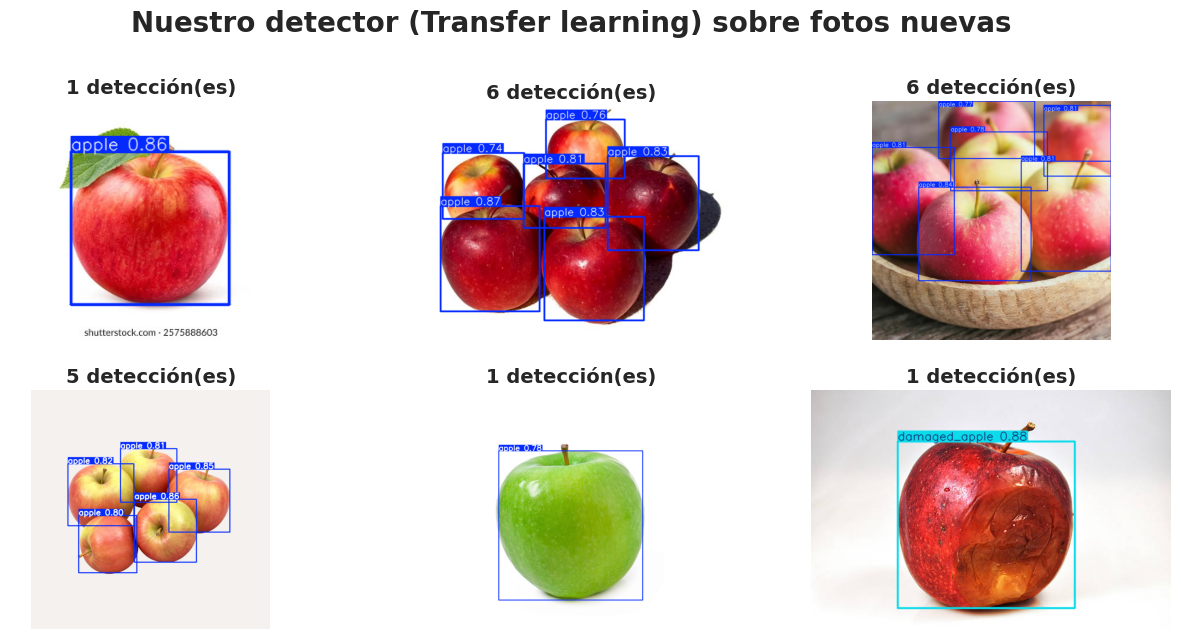

Gráfico guardado: f21_detector_en_fotos.png
Resultados guardados en: /content/resultados_manzanas/imagenes


,imagen,detecciones,clases
0,Manzana 1.jpg,1,apple
1,Manzana 2.jpg,6,apple
2,Manzana 3.jpg,6,apple
3,Manzana 4.jpg,5,apple
4,Manzana 5.jpg,1,apple
5,Manzana podrida 1.jpg,1,damaged_apple
6,Manzana podrida 2.jpg,2,damaged_apple
7,Manzana podrida 3.jpg,1,damaged_apple
8,Manzana podrida 4.jpg,1,apple
9,Manzana podrida 5.jpg,1,damaged_apple


In [33]:
# ============================================================
# PARTE 9A · Imágenes fuera del dataset
# ============================================================
if EJEMPLOS_PROPIOS:
    IMAGENES_EXTERNAS = EJEMPLOS_PROPIOS
else:
    print("AVISO: no hay fotos propias en ejemplos/. Se usan fotos de Test SOLO para que el notebook corra.")
    IMAGENES_EXTERNAS = listar_imagenes(DATOS / "images" / "test")[:6]
tabla_imagenes = predecir_imagenes(RUTA_ELEGIDO, IMAGENES_EXTERNAS, RESULTADOS / "imagenes",
                                   f"Nuestro detector ({ELEGIDO}) sobre fotos nuevas",
                                   "f21_detector_en_fotos.png")
tabla_imagenes


=== Video 1: video_prueba_1.mp4 ===
396 cuadros procesados (13.2 s de video). Velocidad media: 51.1 cuadros por segundo. Guardado en /content/resultados_manzanas/video_1_detectado.mp4


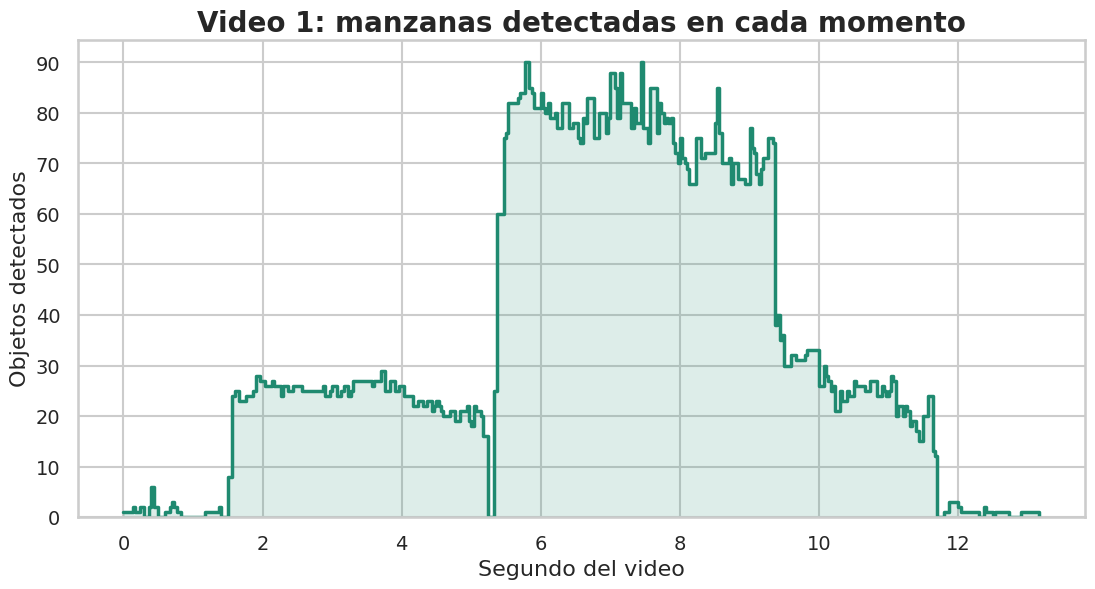

Gráfico guardado: f22_video1_detecciones_por_cuadro.png


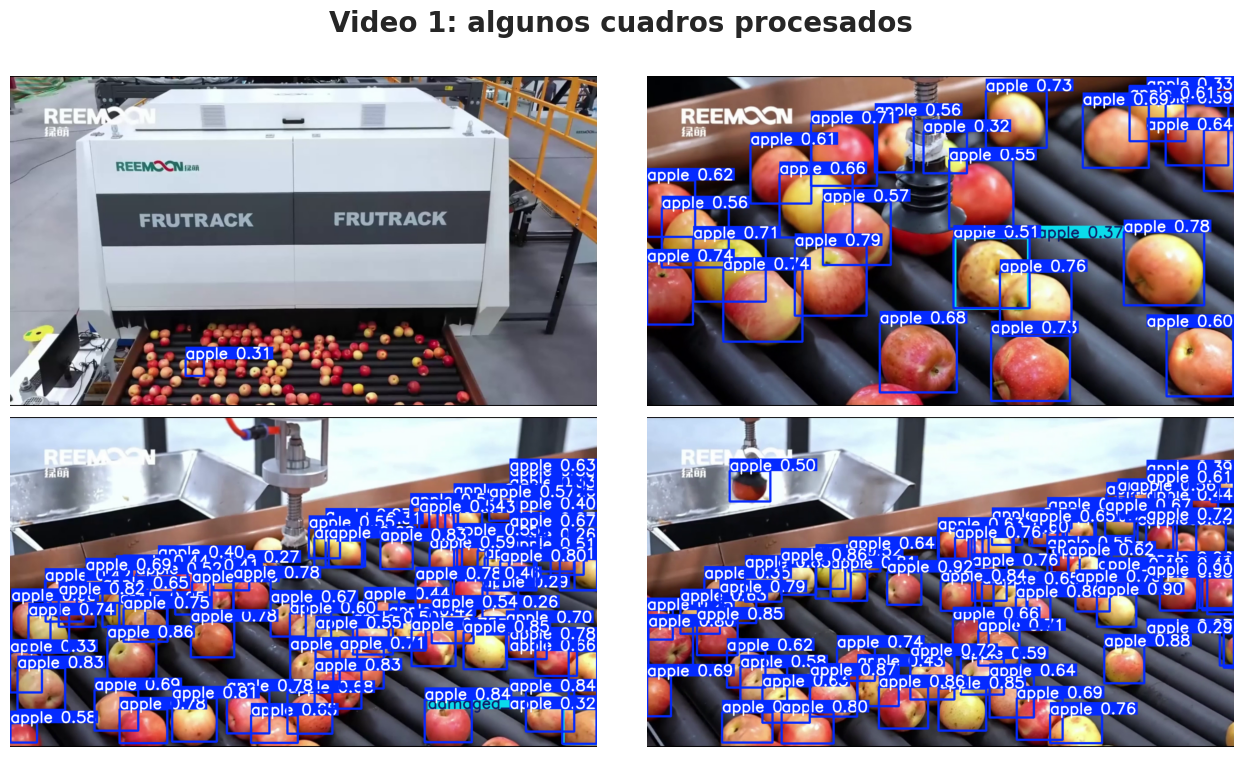

Gráfico guardado: f23_video1_cuadros.png

=== Video 2: video_prueba_2.mp4 ===
319 cuadros procesados (10.6 s de video). Velocidad media: 74.5 cuadros por segundo. Guardado en /content/resultados_manzanas/video_2_detectado.mp4


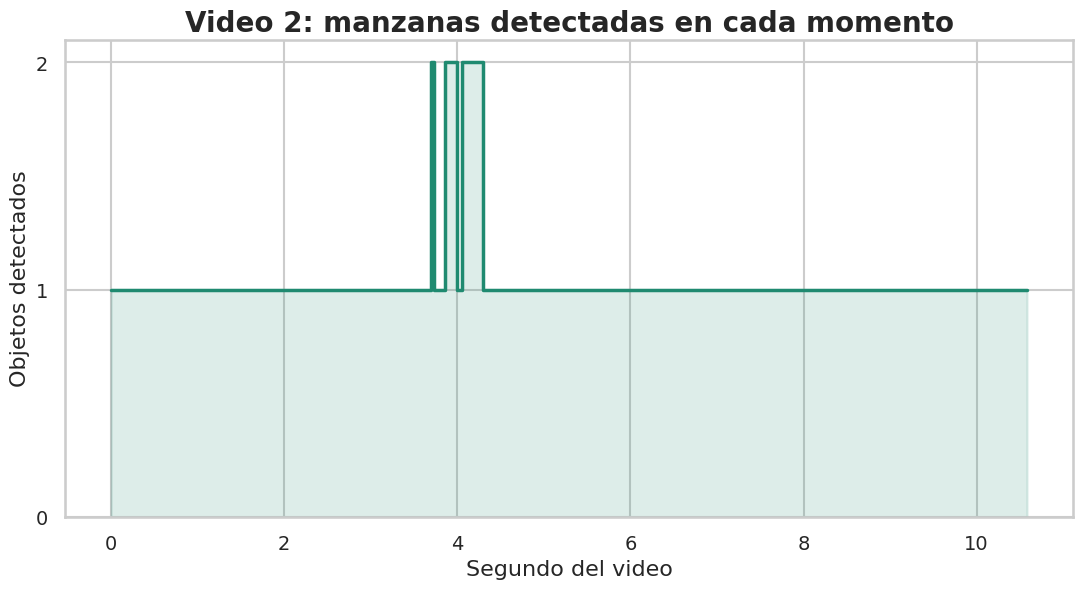

Gráfico guardado: f22_video2_detecciones_por_cuadro.png


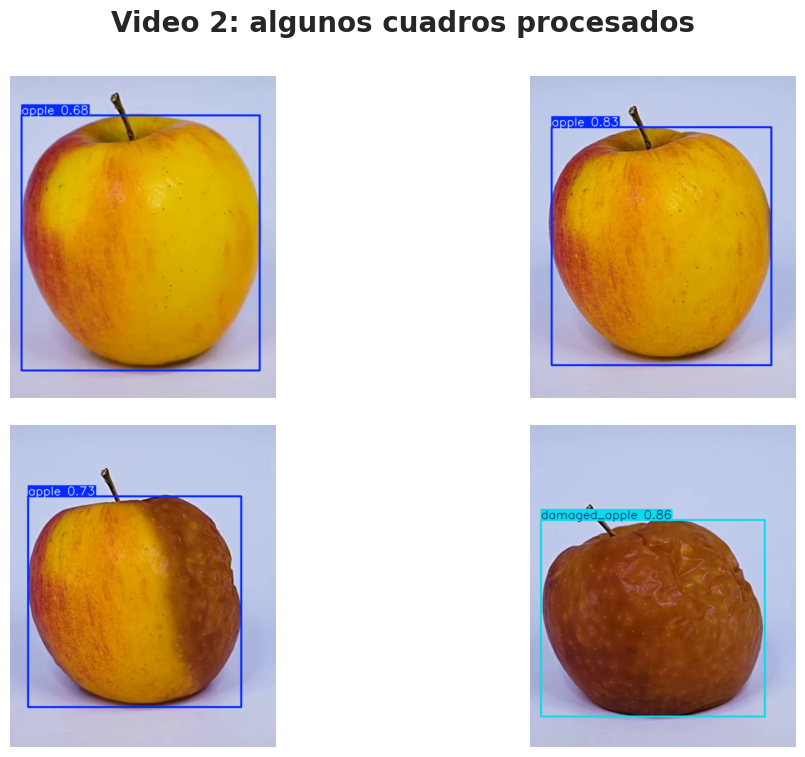

Gráfico guardado: f23_video2_cuadros.png


,cuadros,duracion_s,fps_procesamiento,detecciones_promedio,detecciones_maximas
video,,,,,
video_prueba_1.mp4,396,13.2,51.1,34.8,90
video_prueba_2.mp4,319,10.6,74.5,1.0,2


In [34]:
# ============================================================
# PARTE 9B · Dos videos
# ============================================================
VIDEOS = [BASE / nombre for nombre in PARAMETROS["videos"] if (BASE / nombre).exists()]
if len(VIDEOS) < 2 and CARPETA_EJEMPLOS.exists():              # también sirven .mp4 dentro de ejemplos/
    for extra in sorted(CARPETA_EJEMPLOS.rglob("*.mp4")):
        if extra not in VIDEOS and len(VIDEOS) < 2:
            VIDEOS.append(extra)
if not VIDEOS:
    print("AVISO: no hay videos propios. Se arma uno con fotos de Test SOLO para que el notebook corra; consigan dos videos propios.")
    VIDEOS = [crear_video_desde_imagenes(listar_imagenes(DATOS / "images" / "test")[:10], RESULTADOS / "video_desde_fotos.mp4")]
elif len(VIDEOS) == 1:
    print("AVISO: solo hay 1 video. La Evaluación 04 pide dos: agreguen video_prueba_2.mp4 y vuelvan a ejecutar esta celda.")

RESUMEN_VIDEOS = []
for k, VIDEO in enumerate(VIDEOS, start=1):
    print(f"\n=== Video {k}: {VIDEO.name} ===")
    tabla_video, cuadros = predecir_video(RUTA_ELEGIDO, VIDEO, RESULTADOS / f"video_{k}_detectado.mp4")
    duracion = float(tabla_video["segundo"].max())
    if duracion < 10:
        print(f"AVISO: este video dura {duracion:.1f} s y se piden al menos 10 s.")
    graficar_detecciones_por_cuadro(tabla_video, f"Video {k}: manzanas detectadas en cada momento",
                                    f"f22_video{k}_detecciones_por_cuadro.png")
    galeria_cuadros(cuadros, f"Video {k}: algunos cuadros procesados", f"f23_video{k}_cuadros.png")
    RESUMEN_VIDEOS.append({"video": VIDEO.name, "cuadros": len(tabla_video), "duracion_s": round(duracion, 1),
                           "fps_procesamiento": round(float(1000 / tabla_video["ms"].mean()), 1),
                           "detecciones_promedio": round(float(tabla_video["detecciones"].mean()), 1),
                           "detecciones_maximas": int(tabla_video["detecciones"].max())})
NUMEROS["videos"] = RESUMEN_VIDEOS
pd.DataFrame(RESUMEN_VIDEOS).set_index("video")

---
# Parte 10 · Guardar el modelo y los resultados

Todo lo importante queda en `resultados_manzanas/` y en un ZIP para descargar. **Descárguenlo antes de cerrar Colab**: al cortarse la sesión se borra.

- `modelos/transfer_learning.pt`, `modelos/fine_tuning.pt` y `modelos/modelo_elegido.pt`: los pesos (pocos MB). **`modelo_elegido.pt` es el que se abrirá en vivo en la Evaluación 04.**
- `figuras/`: todos los gráficos (los del informe salen de aquí).
- `numeros_proyecto.json`: las cifras (tiempos, épocas, métricas y errores).
- `imagenes/`, `video_1_detectado.mp4` y `video_2_detectado.mp4`: los resultados de la Parte 9.

Para cargar el modelo después, en cualquier computador: `YOLO("modelo_elegido.pt")`.

In [35]:
# ============================================================
# PARTE 10A · Modelos, cifras y ZIP
# ============================================================
MODELOS = RESULTADOS / "modelos"
MODELOS.mkdir(exist_ok=True)
shutil.copy2(RUTA_TL, MODELOS / "transfer_learning.pt")
shutil.copy2(RUTA_FT, MODELOS / "fine_tuning.pt")
shutil.copy2(RUTA_ELEGIDO, MODELOS / "modelo_elegido.pt")
for run in (RUN_TL, RUN_FT):
    shutil.copy2(run / "results.csv", RESULTADOS / f"results_{run.name}.csv")
NUMEROS["mb_modelo"] = (MODELOS / "modelo_elegido.pt").stat().st_size / 1e6

with open(RESULTADOS / "numeros_proyecto.json", "w", encoding="utf-8") as f:
    json.dump(NUMEROS, f, ensure_ascii=False, indent=2, default=str)

ZIP = BASE / "resultados_manzanas.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in RESULTADOS.rglob("*"):
        if archivo.is_file():
            z.write(archivo, archivo.relative_to(BASE))
print(f"ZIP listo: {ZIP} ({ZIP.stat().st_size / 1e6:.1f} MB)")
print(f"El modelo elegido pesa {NUMEROS['mb_modelo']:.1f} MB")

ZIP listo: /content/resultados_manzanas.zip (80.5 MB)
El modelo elegido pesa 5.5 MB


In [36]:
# ============================================================
# PARTE 10B · Descargar (solo en Colab)
# ============================================================
if Path("/content").exists():
    from google.colab import files
    files.download(str(ZIP))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>